# Did Your Savings Beat Inflation? Nigeria, 2006–2026

Nigerians save in naira bank accounts, fixed deposits, Treasury bills or US dollars.
Inflation often ran far above the interest banks paid, so money in the bank may have
grown in naira while buying less and less.

**Goal:** measure how each common way of saving performed **after inflation**, using
monthly data from the Central Bank of Nigeria (CBN).

> **This is analysis, not financial advice.** Past returns do not predict future returns.

## 1. Setup

**Question:** Do we have the right tools loaded and working?

We use four packages:
- `pandas` for tables of data
- `matplotlib` for charts
- `requests` to download data from the CBN website
- `pathlib` (built into Python) for file and folder paths

In [228]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Folders for the saved data snapshot and the README charts
DATA_DIR = Path("data")
IMAGES_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print("Python:    ", sys.version.split()[0])
print("pandas:    ", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("requests:  ", requests.__version__)

Python:     3.15.0
pandas:     3.1.0
matplotlib: 3.11.2
requests:   2.34.2


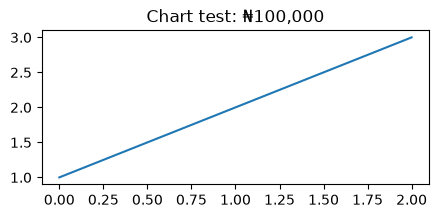

In [229]:
# Quick chart test: matplotlib had font problems on Python 3.15 in an earlier project.
# If this draws a line with the title below, charts work.
fig, ax = plt.subplots(figsize=(5, 2))
ax.plot([1, 2, 3])
ax.set_title("Chart test: ₦100,000")
plt.show()

**Finding:** All packages load and matplotlib can draw a chart, including the naira sign (₦).
The environment is ready for the data pull.

## 2. Data pull from the CBN

**Question:** Can we download 20 years of Nigerian interest rates, inflation and the
naira–dollar exchange rate, and combine them into one clean monthly table?

The CBN website gets its numbers from three **JSON feeds** (an API: a web address that
returns data for programs instead of a page for people):

| Feed | What it holds |
|---|---|
| `GetAllMoneyMarketIndicators` | Monthly interest rates from Jan 2006: savings, fixed deposits, Treasury bills, MPR… |
| `GetAllInflationRates` | Monthly year-on-year inflation from Jan 2003 |
| `GetAllExchangeRates` | Daily official exchange rates for many currencies |

These feeds are **undocumented**, so they could change or disappear. That's why, every
time the download works, we save a **CSV snapshot**. If the download fails, the notebook
loads the snapshot instead, so it still runs offline.

In [230]:
# The CBN data feeds (undocumented, so they could change without notice)
BASE_URL = "https://www.cbn.gov.ng/api/"
FEEDS = {
    "money_market": "GetAllMoneyMarketIndicators",
    "inflation": "GetAllInflationRates",
    "exchange_rates": "GetAllExchangeRates",
}

# Some servers refuse requests that don't look like they come from a web browser
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36"
}

SNAPSHOT_PATH = DATA_DIR / "cbn_savings_data.csv"


def fetch_feed(feed_name):
    """Download one CBN feed and return it as a DataFrame (every value is still text)."""
    response = requests.get(BASE_URL + feed_name, headers=HEADERS, timeout=120)
    response.raise_for_status()  # stop with an error if the server says no (e.g. 404 or 500)
    return pd.DataFrame(response.json())

### Cleaning each feed

The feeds send every number as **text** (for example `"5.36"`), so we convert them with
`pd.to_numeric`. Using `errors="coerce"` turns anything that isn't a number, such as a
blank `""`, into `NaN` (missing) instead of crashing.

The feeds also store dates as two columns, `tyear` and `tmonth`. We combine them into
one `month` date (the 1st of each month), so the three tables can be lined up.

In [231]:
# The interest rate columns in the money market feed (all in % per year)
RATE_COLUMNS = [
    "savingsDeposit", "oneMonthDeposit", "threeMonthsDeposit", "sixMonthsDeposit",
    "twelveMonthsDeposit", "treasuryBill", "mpr", "mrr",
    "interBankCallRate", "primeLending", "maxLending",
]


def add_month_column(df):
    """Combine the tyear and tmonth columns into one date: the 1st of each month."""
    df["month"] = pd.to_datetime({"year": df["tyear"], "month": df["tmonth"], "day": 1})
    return df


def clean_money_market(raw):
    df = add_month_column(raw.copy())
    for col in RATE_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    # The feed is newest-first; sort it oldest-first
    return df[["month"] + RATE_COLUMNS].sort_values("month")


def clean_inflation(raw):
    df = add_month_column(raw.copy())
    # "YearOn" = year-on-year: how much prices rose compared with the same month last year
    df["inflation"] = pd.to_numeric(df["allItemsYearOn"], errors="coerce")
    df["food_inflation"] = pd.to_numeric(df["foodYearOn"], errors="coerce")
    return df[["month", "inflation", "food_inflation"]].sort_values("month")

The exchange rate feed needs more work:
- It holds **every currency**, and some names have stray spaces or tabs
  (`"US DOLLAR"` and `"US DOLLAR "` both appear). We strip those before picking the dollar.
- It is **daily**, but the other feeds are monthly. We take the **average rate of each month**.
- A few days appear twice, so we keep one row per day.

`centralrate` is the CBN's official rate: how many naira one US dollar cost.

In [232]:
def clean_usd(raw):
    df = raw.copy()
    df["currency"] = df["currency"].str.strip()  # remove stray spaces and tabs
    usd = df[df["currency"] == "US DOLLAR"].copy()

    usd["date"] = pd.to_datetime(usd["ratedate"])
    usd["usd_ngn"] = pd.to_numeric(usd["centralrate"], errors="coerce")
    usd = usd.drop_duplicates(subset="date")  # one row per day

    # resample("MS") groups the days into months, dated at the Month Start (the 1st)
    monthly = usd.set_index("date")["usd_ngn"].resample("MS").mean()
    return monthly.reset_index().rename(columns={"date": "month"})

### Download, combine, save (or fall back to the snapshot)

We **merge** the three tables on `month`. The money market table goes first and decides
which months we keep (Jan 2006 onwards), because without interest rates there is nothing
to compare.

`try` / `except` means: *try the download; if a network error happens, run the
`except` part instead.* We only catch download errors (`RequestException`) and broken
JSON (`ValueError`), so a mistake in our own code still shows up as an error.

In [233]:
try:
    print("Downloading CBN feeds (the exchange rate feed is about 8 MB)...")
    money_market = clean_money_market(fetch_feed(FEEDS["money_market"]))
    inflation = clean_inflation(fetch_feed(FEEDS["inflation"]))
    usd = clean_usd(fetch_feed(FEEDS["exchange_rates"]))

    data = (
        money_market
        .merge(inflation, on="month", how="left")
        .merge(usd, on="month", how="left")
    )
    data.to_csv(SNAPSHOT_PATH, index=False)
    print(f"Live data downloaded. Snapshot saved to {SNAPSHOT_PATH}")

except (requests.RequestException, ValueError) as error:
    print(f"Download failed: {error}")
    print(f"Using the saved snapshot instead: {SNAPSHOT_PATH}")
    data = pd.read_csv(SNAPSHOT_PATH, parse_dates=["month"])

Live data downloaded. Snapshot saved to data\cbn_savings_data.csv


In [234]:
print("Rows (months):", len(data))
print("From", data["month"].min().date(), "to", data["month"].max().date())
data.head()

Rows (months): 249
From 2006-01-01 to 2026-09-01


,month,savingsDeposit,oneMonthDeposit,threeMonthsDeposit,sixMonthsDeposit,twelveMonthsDeposit,treasuryBill,mpr,mrr,interBankCallRate,primeLending,maxLending,inflation,food_inflation,usd_ngn
0,2006-01-01,4.50,7.88,9.95,8.55,8.64,13.68,0.0,13.0,27.06,16.69,18.23,10.7,14.7,128.500000
1,2006-02-01,2.96,9.13,9.68,8.95,8.36,11.49,0.0,13.0,5.59,16.57,18.14,10.8,10.5,127.825000
2,2006-03-01,2.98,9.37,9.57,8.61,9.17,9.86,0.0,13.0,7.77,16.30,17.89,12.0,9.3,126.977273
3,2006-04-01,2.98,9.35,10.23,8.78,8.93,8.60,0.0,13.0,1.13,16.25,18.03,12.6,9.6,126.695000
4,2006-05-01,2.95,9.40,10.26,9.16,9.09,6.65,0.0,13.0,1.57,16.97,18.36,10.5,8.6,126.679524


In [235]:
data.tail()

,month,savingsDeposit,oneMonthDeposit,threeMonthsDeposit,sixMonthsDeposit,twelveMonthsDeposit,treasuryBill,mpr,mrr,interBankCallRate,primeLending,maxLending,inflation,food_inflation,usd_ngn
244,2026-05-01,7.24,12.61,9.89,8.51,10.88,15.95,26.5,NaN,NaN,19.10,34.78,15.93,16.96,1369.494706
245,2026-06-01,7.32,12.51,10.05,8.01,10.32,16.16,26.5,NaN,NaN,19.06,33.16,15.91,17.52,1366.490167
246,2026-07-01,7.36,12.31,10.07,7.71,9.74,16.30,26.5,NaN,NaN,19.06,33.16,15.43,20.31,1372.752317
247,2026-08-01,7.46,12.69,10.34,7.56,10.30,16.30,26.5,NaN,22.0,17.86,29.20,15.39,19.57,1352.473120
248,2026-09-01,5.36,12.20,10.33,8.33,10.50,16.24,23.0,NaN,22.0,19.04,32.62,14.63,19.59,1326.807700


**Finding:** We have one clean monthly table: **249 months, January 2006 to September 2026**,
with every rate stored as a number. A first look already tells the story:

- In January 2006 a savings account paid **4.50%** while inflation was **10.7%**.
- One US dollar cost **₦128.50** in January 2006 and about **₦1,327** in September 2026,
  roughly **10 times** as many naira.

A few things to check in the Data Quality section:
- `mpr` shows **0.0** for early 2006. The MPR didn't exist yet, so that means *missing*, not 0%.
- `mrr` is missing for most months, because the MPR replaced it.
- `interBankCallRate` has 5 missing months (we don't use it for savings).
- Some rates jump around a lot (e.g. Treasury bills fell from 13.68% to 6.65% in early 2006,
  and the savings rate fell from 7.46% to 5.36% in the latest month). We'll check whether those are real.

The snapshot is saved in `data/cbn_savings_data.csv`, so the notebook still runs offline.

## 3. Data quality

**Question:** Can we trust these numbers? Are there blanks, fake zeros, typos or
values that disagree with official sources?

One bad number, like a 0% Treasury bill rate, would quietly break every calculation
after it. So before any analysis we check four things:
1. **Blanks:** missing values
2. **Fake zeros:** a `0` that really means "no data"
3. **Spikes:** a value that jumps and snaps back the next month (often a typo)
4. **Spot checks:** a few of our values compared with news and official sources

We keep the original `data` untouched and make our fixes in a copy called `clean`.
Every later section uses `clean`.

In [236]:
clean = data.copy()

# Count blanks and zeros in every column
quality = pd.DataFrame({
    "missing": clean.isna().sum(),
    "zeros": (clean == 0).sum(),
})
quality[(quality["missing"] > 0) | (quality["zeros"] > 0)]

,missing,zeros
treasuryBill,0,2
mpr,0,11
mrr,238,0
interBankCallRate,5,4


Three columns have zeros, and two have blanks. Let's look at each.

### The MPR / MRR switch

Until December 2006, the CBN's main interest rate was the **MRR** (Minimum Rediscount
Rate). From **11 December 2006** it was replaced by the **MPR** (Monetary Policy Rate),
starting at 10%. So in our data:
- `mrr` is blank from December 2006 on (correct: it no longer existed)
- `mpr` is `0.0` before December 2006, which is wrong: the rate didn't exist, it wasn't 0%

In [237]:
clean.loc[(clean["month"] >= "2006-09-01") & (clean["month"] <= "2007-02-01"), ["month", "mpr", "mrr"]]

,month,mpr,mrr
8,2006-09-01,0.0,14.0
9,2006-10-01,0.0,14.0
10,2006-11-01,0.0,14.0
11,2006-12-01,10.0,NaN
12,2007-01-01,10.0,NaN
13,2007-02-01,10.0,NaN


In [238]:
# Before Dec 2006 the MPR didn't exist: replace the fake zeros with NaN (missing)
clean.loc[clean["mpr"] == 0, "mpr"] = float("nan")

print("MPR zeros left:", (clean["mpr"] == 0).sum())
print("First month with an MPR:", clean.loc[clean["mpr"].notna(), "month"].min().date())

MPR zeros left: 0
First month with an MPR: 2006-12-01


### Treasury bill zeros

A 0% Treasury bill rate never happened in Nigeria. The two zeros fall in **December 2017**
and **December 2018**, right between months of 11–13%, so they mean "no figure reported".

We can't leave a gap, because later we compound a return **every month**. So we fill
each gap with the previous month's rate (`ffill`, "forward fill"). This assumes the rate
stayed the same for that one month, which is a small, reasonable guess.

In [239]:
tbill_zero = clean["treasuryBill"] == 0
print("Zero months:", clean.loc[tbill_zero, "month"].dt.strftime("%Y-%m").tolist())

clean.loc[tbill_zero, "treasuryBill"] = float("nan")
clean["treasuryBill"] = clean["treasuryBill"].ffill()

clean.loc[(clean["month"] >= "2017-11-01") & (clean["month"] <= "2018-01-01"), ["month", "treasuryBill"]]

Zero months: ['2017-12', '2018-12']


,month,treasuryBill
142,2017-11-01,13.01
143,2017-12-01,13.01
144,2018-01-01,12.27


### Interbank call rate

`interBankCallRate` (the rate banks charge each other overnight) has 4 zeros and
5 blanks. We don't use it to measure savings, so we only mark the zeros as missing
and leave the gaps.

In [240]:
clean.loc[clean["interBankCallRate"] == 0, "interBankCallRate"] = float("nan")
print("Interbank months missing:", clean["interBankCallRate"].isna().sum())

Interbank months missing: 9


### Spikes: values that jump and snap back

A real rate change usually lasts: when the CBN raises rates, they stay up. A **typo**
tends to appear for one month and disappear. So for each month we compare the value
with the **average of the month before and the month after**. If it is more than
3 percentage points away from that average, we flag it for a closer look.

(We run this *after* fixing the zeros. Otherwise the zeros, and the months next to them,
would fill the list.)

In [241]:
def find_spikes(series, threshold=3):
    """Flag months more than `threshold` points away from the average of their two neighbours."""
    neighbours_avg = (series.shift(1) + series.shift(-1)) / 2
    gap = series - neighbours_avg
    return gap[gap.abs() > threshold]


KEY_COLUMNS = ["savingsDeposit", "twelveMonthsDeposit", "treasuryBill", "mpr", "inflation"]
by_month = clean.set_index("month")

spikes = []
for col in KEY_COLUMNS:
    for month, gap in find_spikes(by_month[col]).items():
        spikes.append({"column": col, "month": month.strftime("%Y-%m"),
                       "value": by_month.loc[month, col], "gap": round(gap, 2)})

pd.DataFrame(spikes)

,column,month,value,gap
0,twelveMonthsDeposit,2009-02,16.47,4.56
1,twelveMonthsDeposit,2009-03,11.44,-4.25
2,twelveMonthsDeposit,2009-04,14.91,3.38
3,twelveMonthsDeposit,2009-11,8.91,-3.84
4,twelveMonthsDeposit,2012-12,10.63,4.50
5,treasuryBill,2011-10,15.00,3.28
6,treasuryBill,2024-01,4.33,-8.65
7,treasuryBill,2024-02,17.03,6.60
8,inflation,2006-07,3.00,-3.10
9,inflation,2024-12,34.80,3.69


A chart helps us judge these. Big moves that **last** are real history. Single-month
blips are suspects.

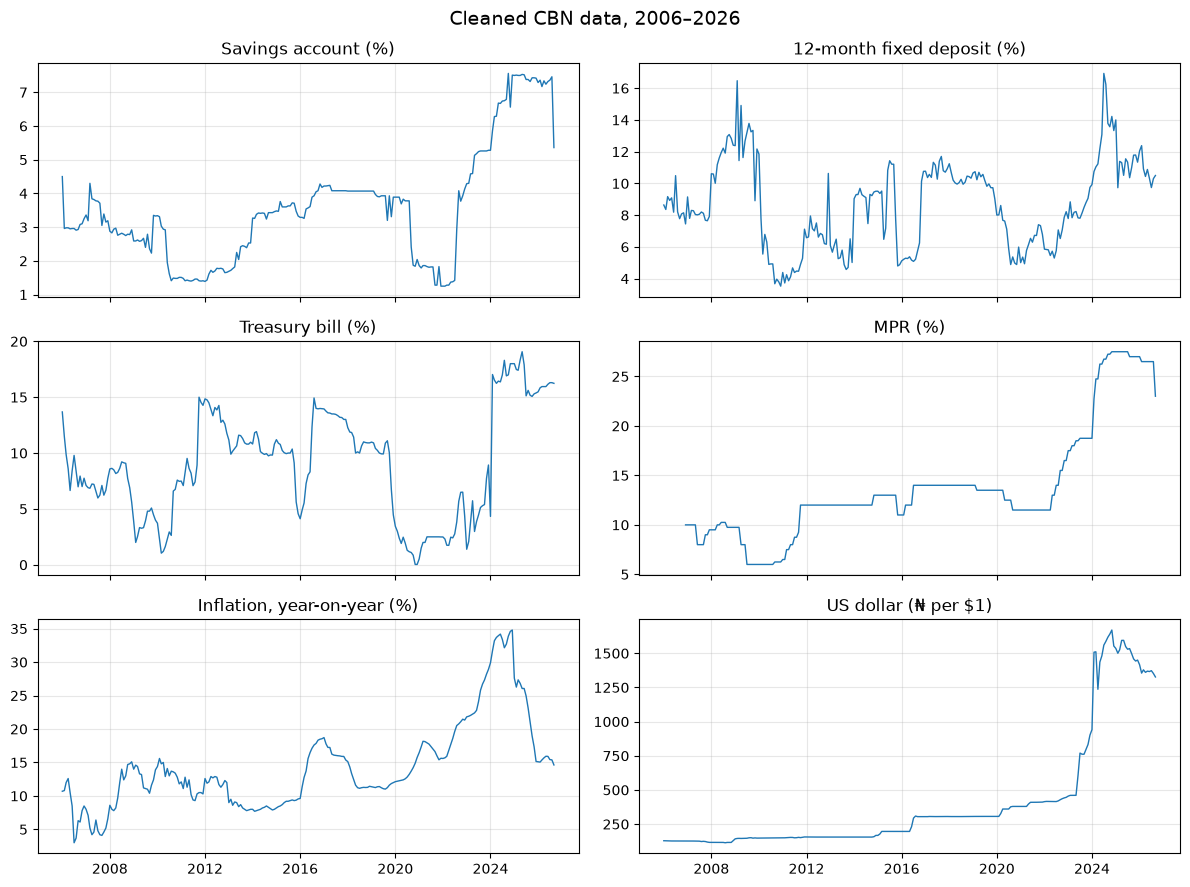

In [242]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
chart_columns = KEY_COLUMNS + ["usd_ngn"]
titles = ["Savings account (%)", "12-month fixed deposit (%)", "Treasury bill (%)",
          "MPR (%)", "Inflation, year-on-year (%)", "US dollar (₦ per $1)"]

for ax, col, title in zip(axes.flat, chart_columns, titles):
    ax.plot(clean["month"], clean[col], linewidth=1)
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig.suptitle("Cleaned CBN data, 2006–2026", fontsize=14)
fig.tight_layout()
plt.show()

**Our verdict on each flag:**

| Flag | Verdict | Action |
|---|---|---|
| Inflation, Jul 2006: 3.0% | A secondary source (Nairametrics) lists the same 3.00%; inflation was low through mid-2006 | Keep |
| Inflation, Dec 2024: 34.8% | NBS published 34.80%. It looks like a spike only because Jan 2025 dropped after the CPI rebasing | Keep (Section 4 handles the rebasing) |
| MPR, Dec 2006 | The MPR began that month | Keep |
| T-bill, Oct 2011 | The MPR jumped 2.75 points that month; T-bills followed | Keep |
| T-bill, Jan → Feb 2024: 4.33% → 17.03% | Matches the Feb 2024 policy shock (MPR +4 points, naira devalued). Rates stayed high afterwards | Keep |
| 12-month deposit, 2009 | Rates bounced for several months during the 2009 banking crisis, not just one | Keep, but note it's noisy |
| 12-month deposit, Dec 2012: 10.63% | A one-month blip between 6.17% and 6.09%, and nothing else moved. Likely a year-end special rate or an error | **Keep for now, but suspect.** It only matters if a fixed deposit is opened in Dec 2012 (Section 8) |

We also note one value we can't check yet: the savings rate fell from 7.46% to 5.36%
in **September 2026**, the newest month. Latest figures are sometimes revised.

### Spot checks against outside sources

| Check | Our data | Outside source | Match? |
|---|---|---|---|
| MPR replaced MRR in Dec 2006 at 10% | Dec 2006: `mpr` 10.0, `mrr` blank | CBN: MPR took effect 11 Dec 2006 at 10% | ✅ |
| Inflation, Dec 2024 | 34.80% | NBS: 34.80% | ✅ |
| Inflation, Aug 2026 | 15.39% | News reports of NBS: 15.39% | ✅ |
| MPR cut, Sep 2026 | 26.5% → 23.0% | CBN MPC, 22 Sep 2026: cut from 26.5% to 23% | ✅ |
| T-bill, Apr 2024 | 16.24% | 91-day stop rate, 24 Apr 2024 auction: 16.24% | ✅ |
| **Inflation, Jan 2025** | **27.61%** | **NBS: 24.48%** | ❌ |

**Which Treasury bill is this?** In March 2024 the CBN's auctions set 17.24% (91-day),
18% (182-day) and 21.49% (364-day). Our March 2024 value is 16.53%, and our April value
(16.24%) is exactly the 91-day stop rate. So `treasuryBill` is the **91-day Treasury bill**.
That means our T-bill saver rolls over every three months.

### The 2025 inflation puzzle

The Jan 2025 spot check failed. Comparing every 2025 month with the figures NBS
published shows that from January to November the CBN feed runs about **3 points higher**.
It also repeats May's value in June. From December 2025 the two agree again.

In [243]:
# Headline inflation as published by the National Bureau of Statistics (NBS),
# taken from news reports of each monthly NBS release
NBS_INFLATION_2025 = {
    "2025-01-01": 24.48,
    "2025-02-01": 23.18,
    "2025-03-01": 24.23,
    "2025-04-01": 23.71,
    "2025-05-01": 22.97,
    "2025-06-01": 22.22,
    "2025-07-01": 21.88,
    "2025-08-01": 20.12,
    "2025-09-01": 18.02,
    "2025-10-01": 16.05,
    "2025-11-01": 14.45,
    "2025-12-01": 15.15,
}

nbs = pd.Series(NBS_INFLATION_2025, name="nbs")
nbs.index = pd.to_datetime(nbs.index)

compare = by_month.loc["2024-12-01":"2026-01-01", ["inflation"]].rename(columns={"inflation": "cbn_feed"})
compare = compare.join(nbs)
compare["difference"] = (compare["cbn_feed"] - compare["nbs"]).round(2)
compare

,cbn_feed,nbs,difference
month,,,
2024-12-01,34.80,NaN,NaN
2025-01-01,27.61,24.48,3.13
2025-02-01,26.27,23.18,3.09
2025-03-01,27.35,24.23,3.12
2025-04-01,26.82,23.71,3.11
2025-05-01,26.06,22.97,3.09
2025-06-01,26.06,22.22,3.84
2025-07-01,24.94,21.88,3.06
2025-08-01,23.14,20.12,3.02


**Our choice:** NBS (the National Bureau of Statistics) is the agency that measures
inflation in Nigeria, and the feed clearly has errors here. So for **January–November 2025**
we replace the feed's values with the official NBS figures.

- The original feed values stay in `data`, so this change is easy to see and undo.
- These 11 numbers were typed in by hand from news reports of each NBS release
  (NAN, Channels TV, Nairametrics, Arise, Guardian, ICIR, VON). They are listed in the README.
- We only fix **headline** inflation. `food_inflation` looks off by a similar amount in 2025
  (e.g. Jan 2025: feed 29.63% vs NBS 26.08%), but we don't use it in the main analysis.

In [244]:
# Swap in the NBS figures for the months listed in NBS_INFLATION_2025.
# (Dec 2025 is in the list too, but both sources agree there, so only 11 values change.)
fix_months = clean["month"].isin(nbs.index)
clean.loc[fix_months, "inflation"] = clean.loc[fix_months, "month"].map(nbs)

print("Months replaced:", fix_months.sum())
clean.loc[fix_months, ["month", "inflation"]].assign(cbn_feed=data.loc[fix_months, "inflation"])

Months replaced: 12


,month,inflation,cbn_feed
228,2025-01-01,24.48,27.61
229,2025-02-01,23.18,26.27
230,2025-03-01,24.23,27.35
231,2025-04-01,23.71,26.82
232,2025-05-01,22.97,26.06
233,2025-06-01,22.22,26.06
234,2025-07-01,21.88,24.94
235,2025-08-01,20.12,23.14
236,2025-09-01,18.02,20.98
237,2025-10-01,16.05,18.97


**Finding:** The data is mostly clean, and most spot checks match outside sources.
- We fixed **11 fake MPR zeros** (before the MPR existed) and **2 fake Treasury bill zeros**
  (Dec 2017 and Dec 2018, filled with the previous month's rate).
- Big jumps in the data are mostly **real history**: the 2016 and 2023–24 naira devaluations,
  the Feb 2024 rate hikes and the 2009 banking crisis. One suspect remains: a one-month
  blip in the 12-month deposit rate in Dec 2012 (10.63%).
- `treasuryBill` is the **91-day** Treasury bill, so the T-bill saver rolls over every 3 months.
- For **Jan–Nov 2025**, the CBN feed's inflation was about **3 points above** the official NBS
  figures, and June repeated May. We replaced those 11 months with the NBS figures.
  Without this fix, 2025 would look worse for savers than it really was.

`clean` is now ready for the price index in Section 4.

## 4. Price index

**Question:** How much have prices risen since January 2006? And how do we turn
"₦100,000 today" into "what that buys in 2006 money"?

An inflation rate like *"15% this year"* tells us how **fast** prices rose. To compare
2006 with 2026 we need the price **level**: one number per month for the cost of a
typical basket of goods. That's a **price index** (CPI, Consumer Price Index).

If the index is 100 in Jan 2006 and 1,500 today, the same basket costs **15 times** as
much, so ₦1.5m today buys what ₦100,000 bought in 2006.

**Is there an official index we can download?** No. The CBN's inflation feed has only
rates, and the "Inflation Monitor" link on the CBN rates page is broken. So we
**build an approximate index** from the year-on-year rates.

### The method: turn yearly rates into monthly steps

A year-on-year rate of 12% means prices are 12% higher than 12 months ago. If prices
rose at the same pace every month, the monthly rise `m` would satisfy
`(1 + m) ** 12 = 1.12`, so:

`m = (1 + yoy/100) ** (1/12) - 1`

Then we **chain** the months: start at 100 in Jan 2006 and multiply by `(1 + m)` each
month. This is the same compounding idea we'll use for savings, applied to prices.

In [245]:
# Example: 12% a year is a bit less than 1% a month (not 12 / 12 = 1%, because of compounding)
yoy_example = 12
monthly_example = (1 + yoy_example / 100) ** (1 / 12) - 1
print(f"{yoy_example}% a year = {monthly_example:.3%} a month")
print(f"Check: 12 months of that = {(1 + monthly_example) ** 12 - 1:.1%}")

12% a year = 0.949% a month
Check: 12 months of that = 12.0%


In [246]:
# Monthly inflation as a fraction (0.01 = 1%), from each month's year-on-year rate
clean["monthly_inflation"] = (1 + clean["inflation"] / 100) ** (1 / 12) - 1

# Chain the months. Jan 2006 is the starting point (100), so its own step doesn't count.
growth = 1 + clean["monthly_inflation"]
growth.iloc[0] = 1
clean["price_index"] = 100 * growth.cumprod()

clean.loc[clean["month"].dt.month == 1, ["month", "inflation", "price_index"]].round(1)

C:\Users\HP\AppData\Local\Temp\ipykernel_16552\3996180697.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  clean.loc[clean["month"].dt.month == 1, ["month", "inflation", "price_index"]].round(1)


,month,inflation,price_index
0,2006-01-01,10.7,100.0
12,2007-01-01,8.0,108.1
24,2008-01-01,8.6,114.0
36,2009-01-01,14.0,127.6
48,2010-01-01,14.4,143.7
60,2011-01-01,12.1,163.2
72,2012-01-01,12.6,181.0
84,2013-01-01,9.0,202.6
96,2014-01-01,8.0,219.7
108,2015-01-01,8.2,237.4


In [247]:
start_index = clean["price_index"].iloc[0]
latest_index = clean["price_index"].iloc[-1]
latest_month = clean["month"].iloc[-1].strftime("%B %Y")

print(f"Prices in {latest_month} are {latest_index / start_index:.1f} times their Jan 2006 level.")
print(f"To buy what ₦100,000 bought in Jan 2006, you need about ₦{100_000 * latest_index / start_index:,.0f}.")

Prices in September 2026 are 15.1 times their Jan 2006 level.
To buy what ₦100,000 bought in Jan 2006, you need about ₦1,512,975.


### The January 2025 rebasing

In January 2025, NBS **rebased** the CPI: it changed the basket of goods (food's share
fell from about 52% to 40%) and restarted the official index around 100. That's why
inflation dropped from 34.8% in December 2024 to 24.5% in January 2025.

If we had downloaded the official index *levels*, they would suddenly fall from about 1,000
to about 110 in Jan 2025. Then we would have to **chain-link** them: join the new index
to the old one using the overlap, instead of restarting.

Because we build our index from **rates**, it is chain-linked automatically: we keep
multiplying across the break, and nothing restarts. The one choice we make is to accept
the new-method rates from 2025 as they are. Part of the 2025 drop came from the method
change rather than slower price rises, but no official figure separates the two.

### Check 1: does our index reproduce the reported inflation?

If our index were perfect, its 12-month growth would equal the reported year-on-year rate
every month. Let's compare them.

Average gap: 2.0 points.  Largest: 8.8 points in Feb 2025


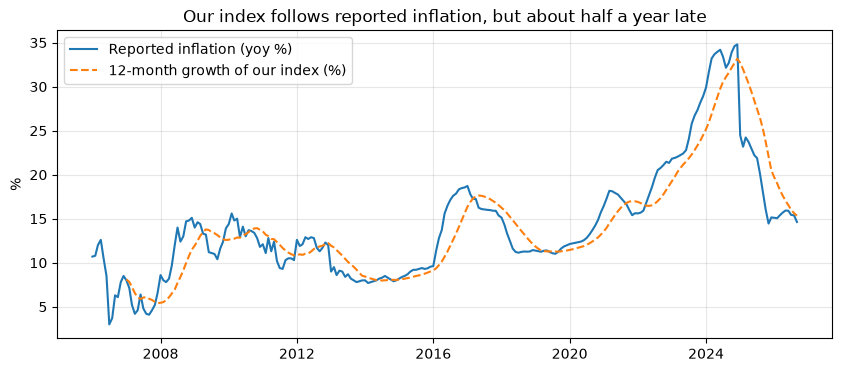

In [248]:
clean["index_yoy"] = clean["price_index"].pct_change(12) * 100
gap = (clean["index_yoy"] - clean["inflation"]).abs()
print(f"Average gap: {gap.mean():.1f} points.  Largest: {gap.max():.1f} points in {clean.loc[gap.idxmax(), 'month']:%b %Y}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clean["month"], clean["inflation"], label="Reported inflation (yoy %)")
ax.plot(clean["month"], clean["index_yoy"], label="12-month growth of our index (%)", linestyle="--")
ax.set_title("Our index follows reported inflation, but about half a year late")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The dashed line runs **behind** the solid one. That's the weakness of this method:
each yoy rate describes the **past 12 months**, but we apply it as if it all happened
in one month. So when inflation changes fast (2016, 2023–24, the 2025 drop), our index
reacts late.

### Check 2: a different method, the 12-month chain

There's another way to build the index that has no lag: use the yoy rate exactly as
it is defined, **price this month = price 12 months ago × (1 + yoy)**. It needs 12
starting values, so we borrow the first year from our index.

In [249]:
chain_index = clean["price_index"].to_list()
yoy = clean["inflation"].to_list()
for t in range(12, len(chain_index)):
    chain_index[t] = chain_index[t - 12] * (1 + yoy[t] / 100)
clean["price_index_12m"] = chain_index

falling_months = (clean["price_index_12m"].diff() < 0).sum()
print(f"The 12-month chain shows prices FALLING in {falling_months} of {len(clean)} months.")

checkpoints = clean[clean["month"].isin(pd.to_datetime(
    ["2008-01-01", "2011-01-01", "2016-01-01", "2021-01-01", "2024-01-01", "2025-01-01", "2026-09-01"]))]
checkpoints[["month", "price_index", "price_index_12m"]].assign(
    ratio=checkpoints["price_index_12m"] / checkpoints["price_index"]).round(3)

The 12-month chain shows prices FALLING in 70 of 249 months.


C:\Users\HP\AppData\Local\Temp\ipykernel_16552\353939340.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ratio=checkpoints["price_index_12m"] / checkpoints["price_index"]).round(3)


,month,price_index,price_index_12m,ratio
24,2008-01-01,114.012,117.288,1.029
60,2011-01-01,163.219,171.471,1.051
120,2016-01-01,259.083,269.585,1.041
180,2021-01-01,496.018,535.935,1.080
216,2024-01-01,865.601,980.388,1.133
228,2025-01-01,1148.663,1220.387,1.062
248,2026-09-01,1512.975,1507.354,0.996


The 12-month chain has no lag, but it zigzags: prices "fall" in about 70 months, which
didn't happen. Its guessed first year repeats every year after that. So we **keep our
smooth index**, and use the chain only to measure how far off we might be:
- **At the end (Sep 2026) the two agree within about 0.5%**, so the headline
  "₦100,000 then vs now" is solid.
- **In between they differ by up to about 13%** (early 2024, right after inflation surged).
  Real values in the middle of the period are approximate.

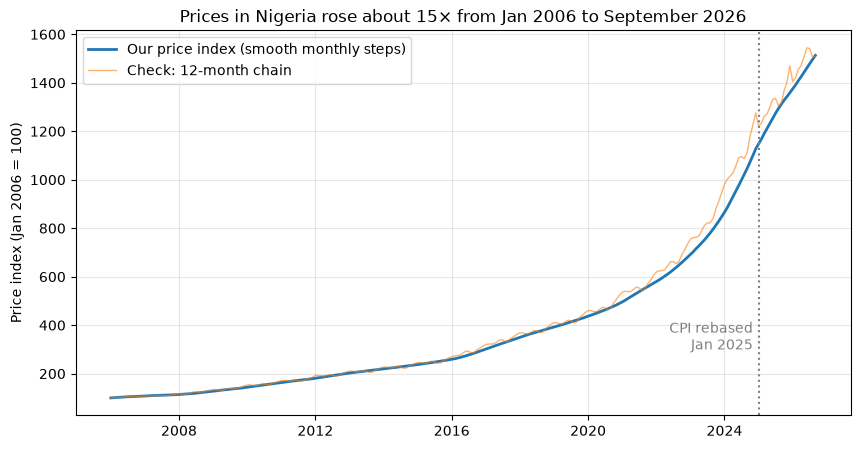

In [250]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(clean["month"], clean["price_index"], label="Our price index (smooth monthly steps)", linewidth=2)
ax.plot(clean["month"], clean["price_index_12m"], label="Check: 12-month chain", linewidth=1, alpha=0.6)
ax.axvline(pd.Timestamp("2025-01-01"), color="grey", linestyle=":")
ax.text(pd.Timestamp("2024-11-01"), 300, "CPI rebased\nJan 2025", ha="right", color="grey")
ax.set_title(f"Prices in Nigeria rose about {latest_index / start_index:.0f}× from Jan 2006 to {latest_month}")
ax.set_ylabel("Price index (Jan 2006 = 100)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(IMAGES_DIR / "price_index.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Prices in Nigeria rose about **15 times** between January 2006 and September 2026.
To buy what ₦100,000 bought in January 2006, you need about **₦1.5 million** today.

This index is an **approximation**, built from year-on-year inflation rates because no
CBN index feed exists:
- It **lags** reported inflation by about half a year, so it reacts late to sudden changes.
- A second method agrees on the overall rise within about 0.5%, but differs by up to about
  13% in between. So the **start-to-end results are reliable, and mid-period values are rough**.
- It runs straight across the **January 2025 rebasing** without restarting (chain-linked),
  using the official new-method rates from 2025.

## 5. Real interest rates

**Question:** In how many months did savings accounts, fixed deposits and Treasury bills
pay **less than inflation**? When were the worst stretches?

A bank's interest rate is a **nominal** rate: how many more naira you get back. What
matters is whether those naira **buy more**. That's the **real** interest rate, the
rate after inflation. We use the **Fisher formula**:

`real rate = (1 + interest rate) / (1 + inflation) − 1`

A **negative real rate** means your balance grows in naira but buys less.

(Simply subtracting, *rate − inflation*, is a common shortcut. It gets less accurate
as inflation rises, so with Nigerian inflation we use the exact formula.)

In [251]:
# Example: 5% interest while prices rise 15%
rate, inflation_rate = 5, 15
real = (1 + rate / 100) / (1 + inflation_rate / 100) - 1
print(f"Exact (Fisher): {real:.1%}   Shortcut (subtract): {rate - inflation_rate}%")

Exact (Fisher): -8.7%   Shortcut (subtract): -10%


We compare each option's interest rate with the inflation rate **in the same month**.
Both are yearly rates, so the result is also a yearly real rate.

**Cash at home** earns 0%, so its real rate is pure inflation loss. **US dollars**
don't pay interest. Their return comes from the exchange rate, so they get their own
section (Section 7).

We also fix one **colour for each option**, used in every chart from here on.

In [252]:
# Savings options and the column holding each one's interest rate (% per year)
OPTIONS = {
    "Cash at home": None,  # earns nothing
    "Savings account": "savingsDeposit",
    "12-month fixed deposit": "twelveMonthsDeposit",
    "Treasury bill (91-day)": "treasuryBill",
}

# One colour per option, used in every chart (cash is grey: it's the "do nothing" baseline)
OPTION_COLORS = {
    "Cash at home": "#898781",
    "Savings account": "#2a78d6",
    "12-month fixed deposit": "#eb6834",
    "Treasury bill (91-day)": "#1baf7a",
    "US dollars": "#eda100",
}

monthly = clean.set_index("month")

real_rates = pd.DataFrame(index=monthly.index)
for option, column in OPTIONS.items():
    nominal = 0 if column is None else monthly[column]
    real_rates[option] = ((1 + nominal / 100) / (1 + monthly["inflation"] / 100) - 1) * 100

real_rates.tail().round(1)

,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day)
month,,,,
2026-05-01,-13.7,-7.5,-4.4,0.0
2026-06-01,-13.7,-7.4,-4.8,0.2
2026-07-01,-13.4,-7.0,-4.9,0.8
2026-08-01,-13.3,-6.9,-4.4,0.8
2026-09-01,-12.8,-8.1,-3.6,1.4


In [253]:
negative = real_rates < 0

summary = pd.DataFrame({
    "negative months": negative.sum(),
    "out of": len(real_rates),
    "% of months negative": (negative.mean() * 100).round(1),
    "worst real rate (%)": real_rates.min().round(1),
    "worst month": real_rates.idxmin().dt.strftime("%b %Y"),
})
summary

,negative months,out of,% of months negative,worst real rate (%),worst month
Cash at home,249,249,100.0,-25.8,Dec 2024
Savings account,249,249,100.0,-20.8,Nov 2024
12-month fixed deposit,202,249,81.1,-16.8,Apr 2024
Treasury bill (91-day),173,249,69.5,-19.7,Jan 2024


### The longest losing stretch

A single bad month matters less than a long run of them. A **stretch** is a run of
back-to-back months with a negative real rate. We walk through the months one by one,
counting how long each run lasts and remembering the longest.

In [254]:
def longest_negative_stretch(real_rate):
    """Return (length, first month, last month) of the longest run of negative values."""
    best_length, best_start, best_end = 0, None, None
    length, start = 0, None
    for month, value in real_rate.items():
        if value < 0:
            if length == 0:
                start = month  # a new run begins
            length += 1
            if length > best_length:
                best_length, best_start, best_end = length, start, month
        else:
            length = 0  # the run is broken
    return best_length, best_start, best_end


latest = real_rates.index[-1]
stretches = []
for option in real_rates.columns:
    length, start, end = longest_negative_stretch(real_rates[option])
    stretches.append({
        "option": option,
        "months": length,
        "years": round(length / 12, 1),
        "from": start.strftime("%b %Y"),
        "to": "still going" if end == latest else end.strftime("%b %Y"),
    })

pd.DataFrame(stretches)

,option,months,years,from,to
0,Cash at home,249,20.8,Jan 2006,still going
1,Savings account,249,20.8,Jan 2006,still going
2,12-month fixed deposit,132,11.0,Oct 2015,still going
3,Treasury bill (91-day),121,10.1,Oct 2015,Oct 2025


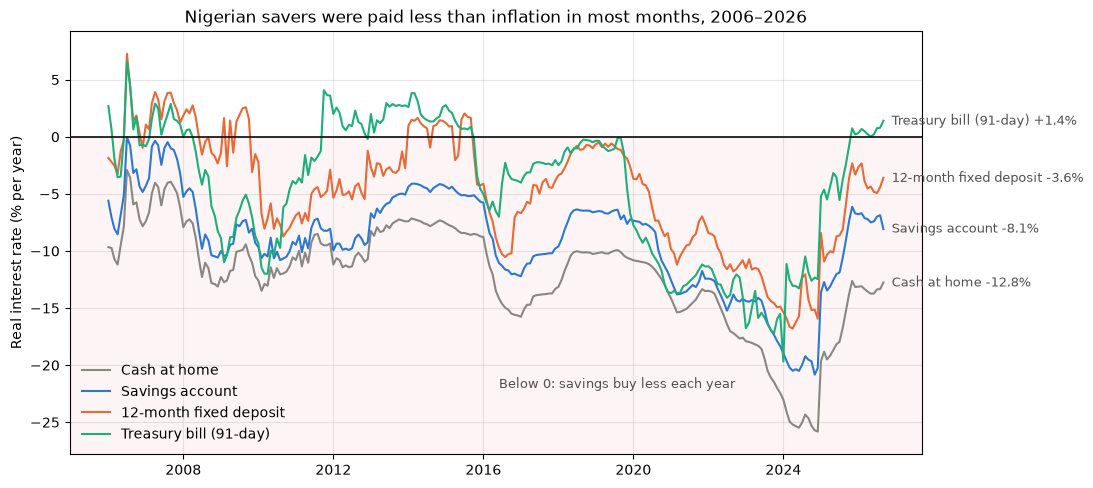

In [255]:
fig, ax = plt.subplots(figsize=(11, 5.5))

for option in real_rates.columns:
    ax.plot(real_rates.index, real_rates[option], color=OPTION_COLORS[option], linewidth=1.5, label=option)
    # Label each line at its right end, so the chart doesn't depend on colour alone
    ax.annotate(f"{option} {real_rates[option].iloc[-1]:+.1f}%",
                xy=(real_rates.index[-1], real_rates[option].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")

ax.axhline(0, color="#0b0b0b", linewidth=1.2)
ax.axhspan(real_rates.min().min() - 2, 0, color="#e34948", alpha=0.05)
ax.text(pd.Timestamp("2016-06-01"), -22, "Below 0: savings buy less each year", fontsize=9, color="#52514e")

ax.set_title("Nigerian savers were paid less than inflation in most months, 2006–2026")
ax.set_ylabel("Real interest rate (% per year)")
ax.set_ylim(real_rates.min().min() - 2, max(real_rates.max().max() + 2, 5))
ax.grid(alpha=0.3)
ax.legend(loc="lower left", frameon=False)
fig.savefig(IMAGES_DIR / "real_rates.png", dpi=150, bbox_inches="tight")
plt.show()

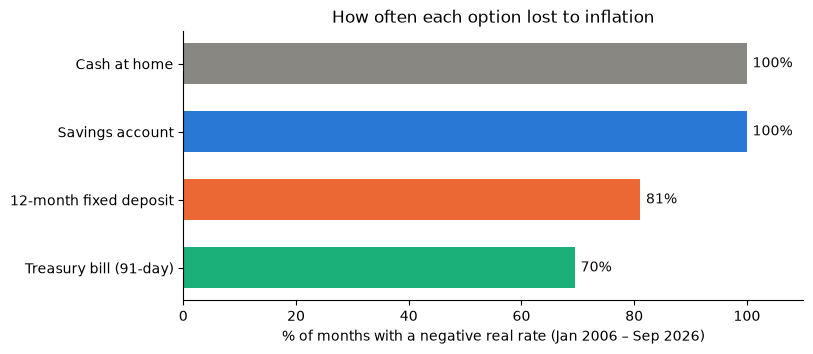

In [256]:
share_negative = summary["% of months negative"]

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(share_negative.index, share_negative.values,
               color=[OPTION_COLORS[o] for o in share_negative.index], height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in share_negative.values], padding=4, color="#0b0b0b")
ax.invert_yaxis()  # first option at the top
ax.set_xlim(0, 110)
ax.set_xlabel("% of months with a negative real rate (Jan 2006 – Sep 2026)")
ax.set_title("How often each option lost to inflation")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGES_DIR / "share_negative.png", dpi=150, bbox_inches="tight")
plt.show()

To see the **worst periods** more clearly, we average the real rate over each year.

In [257]:
yearly_real = real_rates.groupby(real_rates.index.year).mean().round(1)
yearly_real.index.name = "year"
yearly_real

,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day)
year,,,,
2006,-7.7,-4.8,0.2,0.5
2007,-5.1,-1.8,2.6,1.3
2008,-10.3,-7.7,0.3,-2.9
2009,-11.2,-8.8,0.2,-7.8
2010,-12.1,-10.2,-7.1,-8.7
2011,-9.8,-8.5,-5.6,-1.0
2012,-10.9,-9.4,-4.5,1.2
2013,-7.8,-5.8,-2.7,2.2
2014,-7.5,-4.3,1.0,2.3


**Finding:** For most of the last 20 years, Nigerian savers were paid **less than inflation**.
- A **savings account** had a negative real rate in **every one of the 249 months**. Its worst
  month was Nov 2024, at about **−21%** a year.
- A **12-month fixed deposit** lost to inflation in **81%** of months. Its losing stretch
  has run since **Oct 2015 and is still going**, 11 years.
- **Treasury bills** did best but still lost in **70%** of months, including a **10-year
  stretch (Oct 2015 – Oct 2025)**. They turned positive again from Nov 2025, as inflation fell.
- The worst years were **2021–2024**, when inflation climbed past 30% while deposit rates
  barely moved.

Note: we compare this month's interest rate with inflation over the past 12 months. That is
the usual way to measure real rates, but it describes what savers *got*, not what they
expected when they saved.

## 6. The ₦100,000 journey

**Question:** If someone saved ₦100,000 in January 2006, what would it be worth today in
each option, in naira and in **2006 purchasing power**?

Three ideas we need:
1. **Compounding:** each month's interest joins the balance, so next month earns interest
   on a bigger amount. Multiplying all the monthly growth steps together is `cumprod()`,
   the same tool we used for the price index.
2. **Rollovers:** a fixed deposit **locks** its rate for 12 months; then you reinvest at
   whatever the rate is then. A 91-day Treasury bill locks for about 3 months.
3. **Real value:** naira value ÷ price index × 100 converts it into **January 2006 naira**,
   what the money can actually buy.

**Assumptions** (kept simple on purpose):

| Option | How it grows |
|---|---|
| Cash at home | Doesn't grow |
| Savings account | Interest added every month at rate ÷ 12 |
| 12-month fixed deposit | Rate locked every January for 12 months, then rolled over |
| Treasury bill (91-day) | Rate locked for 3 months (≈ 91 days), then rolled over |
| US dollars | ₦100,000 converted at the Jan 2006 official rate, then held as cash dollars |

No fees and no tax. Dollars use the **official** CBN rate. Before the 2023 float, the
parallel-market rate was often much higher, and many savers couldn't buy at the official rate.

### Locked rates

For the fixed deposit and the T-bill, the rate that counts is the one on the day you
rolled over, not this month's rate. `locked_rate` keeps the rate only in rollover months
and carries it forward (`ffill`) until the next rollover.

In [258]:
def locked_rate(rate, term_months):
    """The rate fixed at the most recent rollover.

    Rollovers happen every `term_months` months, counting from the first month of `rate`,
    so the same function works for a saver who starts in any month.
    """
    months_since_start = pd.Series(range(len(rate)), index=rate.index)
    is_rollover = months_since_start % term_months == 0
    return rate.where(is_rollover).ffill()


fd_rate = locked_rate(monthly["twelveMonthsDeposit"], 12)
pd.DataFrame({"12m deposit, this month": monthly["twelveMonthsDeposit"], "12m deposit, locked": fd_rate}).head(14)

,"12m deposit, this month","12m deposit, locked"
month,,
2006-01-01,8.64,8.64
2006-02-01,8.36,8.64
2006-03-01,9.17,8.64
2006-04-01,8.93,8.64
2006-05-01,9.09,8.64
2006-06-01,8.19,8.64
2006-07-01,10.49,8.64
2006-08-01,8.21,8.64
2006-09-01,7.78,8.64


### Monthly growth steps

A growth step of `1.01` means "the balance grew 1% this month".

- Interest earned **during** a month uses the rate in force at the **start** of that month,
  which is the previous row. That's what `.shift(1)` does: it moves each rate down one row.
- For the fixed deposit and T-bill, we spread each term's interest evenly over its months,
  so the line moves smoothly. At the end of each term the saver has exactly what the bank
  would pay: a 12-month deposit at 10% grows by `1.10 ** (1/12)` each month, which makes
  exactly 10% after 12 months.

We put this in a function, `growth_path`, because Section 8 reuses it for savers who
start in other months.

In [259]:
def growth_path(window):
    """How ₦1 saved in the first month of `window` grows in each option, month by month (in naira)."""
    steps = pd.DataFrame(index=window.index)
    steps["Cash at home"] = 1.0
    steps["Savings account"] = 1 + window["savingsDeposit"].shift(1) / 100 / 12
    steps["12-month fixed deposit"] = (1 + locked_rate(window["twelveMonthsDeposit"], 12).shift(1) / 100) ** (1 / 12)
    # A 91-day bill earns a quarter-year's interest, spread over 3 months
    steps["Treasury bill (91-day)"] = (1 + locked_rate(window["treasuryBill"], 3).shift(1) / 100 / 4) ** (1 / 3)
    steps.iloc[0] = 1.0  # the first month is the starting point: no growth yet
    path = steps.cumprod()

    # Dollars: bought at the first month's rate; their naira value moves with the exchange rate
    path["US dollars"] = window["usd_ngn"] / window["usd_ngn"].iloc[0]
    return path


START_AMOUNT = 100_000
nominal_value = START_AMOUNT * growth_path(monthly)
print(f"₦{START_AMOUNT:,} bought ${START_AMOUNT / monthly['usd_ngn'].iloc[0]:,.2f} in Jan 2006")

nominal_value.iloc[::60].round(0)  # every 5 years

₦100,000 bought $778.21 in Jan 2006


,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day),US dollars
month,,,,,
2006-01-01,100000.0,100000.0,100000.0,100000.0,100000.0
2011-01-01,100000.0,115460.0,164867.0,138335.0,116361.0
2016-01-01,100000.0,130457.0,232371.0,238466.0,152957.0
2021-01-01,100000.0,157718.0,359753.0,376450.0,295331.0
2026-01-01,100000.0,198456.0,540215.0,556634.0,1101962.0


### From naira to buying power

Our price index is 100 in Jan 2006. If it's 1,500 today, prices are 15× higher, so
today's naira are worth 100 / 1,500 of a 2006 naira.

In [260]:
real_value = nominal_value.mul(100 / monthly["price_index"], axis=0)
real_value.iloc[::60].round(0)

,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day),US dollars
month,,,,,
2006-01-01,100000.0,100000.0,100000.0,100000.0,100000.0
2011-01-01,61267.0,70739.0,101009.0,84754.0,71292.0
2016-01-01,38598.0,50353.0,89690.0,92043.0,59038.0
2021-01-01,20161.0,31797.0,72528.0,75895.0,59540.0
2026-01-01,7273.0,14433.0,39289.0,40483.0,80144.0


### Annualised return (CAGR)

"Lost 60% over 20 years" is hard to compare with "gained 5% last year". The **compound
annual growth rate** (CAGR) turns any total change into a steady yearly rate:

`CAGR = (end value / start value) ** (1 / years) − 1`

We'll use it again in Sections 7 and 8 to compare different time periods fairly.

In [261]:
def cagr(start_value, end_value, years):
    """The steady yearly growth rate that turns start_value into end_value."""
    return (end_value / start_value) ** (1 / years) - 1


years = (len(monthly) - 1) / 12  # Jan 2006 to Sep 2026

journey = pd.DataFrame({
    "naira today": nominal_value.iloc[-1].round(0),
    "in Jan 2006 naira": real_value.iloc[-1].round(0),
    "% of buying power kept": (real_value.iloc[-1] / START_AMOUNT * 100).round(1),
    "CAGR in naira (%)": (cagr(START_AMOUNT, nominal_value.iloc[-1], years) * 100).round(1),
    "CAGR after inflation (%)": (cagr(START_AMOUNT, real_value.iloc[-1], years) * 100).round(1),
})
print(f"Jan 2006 to {latest_month}: {years:.1f} years")
journey

Jan 2006 to September 2026: 20.7 years


,naira today,in Jan 2006 naira,% of buying power kept,CAGR in naira (%),CAGR after inflation (%)
Cash at home,100000.0,6609.0,6.6,0.0,-12.3
Savings account,208347.0,13771.0,13.8,3.6,-9.1
12-month fixed deposit,582785.0,38519.0,38.5,8.9,-4.5
Treasury bill (91-day),617455.0,40811.0,40.8,9.2,-4.2
US dollars,1032535.0,68245.0,68.2,12.0,-1.8


### Charts

First, a helper that writes each line's name and final value just to the right of the
chart, nudging labels apart so they don't overlap.

In [262]:
from matplotlib.transforms import blended_transform_factory


def label_line_ends(ax, end_values, value_format):
    """Label each line at the right edge of the chart, spreading labels so they don't overlap."""
    low, high = ax.get_ylim()
    min_gap = (high - low) * 0.05
    right_edge = blended_transform_factory(ax.transAxes, ax.transData)  # x in chart width, y in data
    previous_y = None
    for name, value in sorted(end_values.items(), key=lambda item: item[1]):
        y = value if previous_y is None else max(value, previous_y + min_gap)
        ax.text(1.01, y, f"{name}  {value_format.format(value)}", transform=right_edge,
                va="center", fontsize=9, color="#52514e")
        previous_y = y

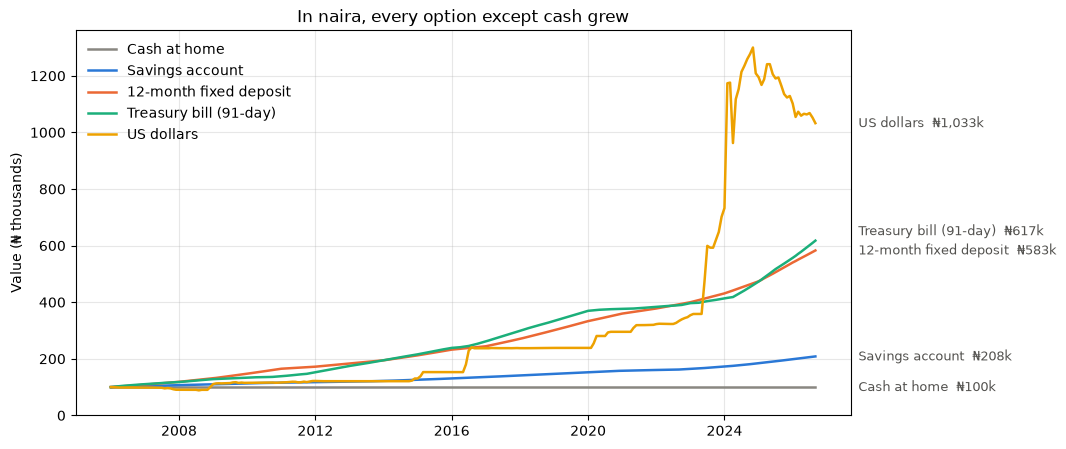

In [263]:
fig, ax = plt.subplots(figsize=(10, 5))
for option in nominal_value.columns:
    ax.plot(nominal_value.index, nominal_value[option] / 1000, color=OPTION_COLORS[option], linewidth=1.8, label=option)

ax.set_title("In naira, every option except cash grew")
ax.set_ylabel("Value (₦ thousands)")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend(loc="upper left", frameon=False)
label_line_ends(ax, (nominal_value.iloc[-1] / 1000).to_dict(), "₦{:,.0f}k")
fig.savefig(IMAGES_DIR / "journey_nominal.png", dpi=150, bbox_inches="tight")
plt.show()

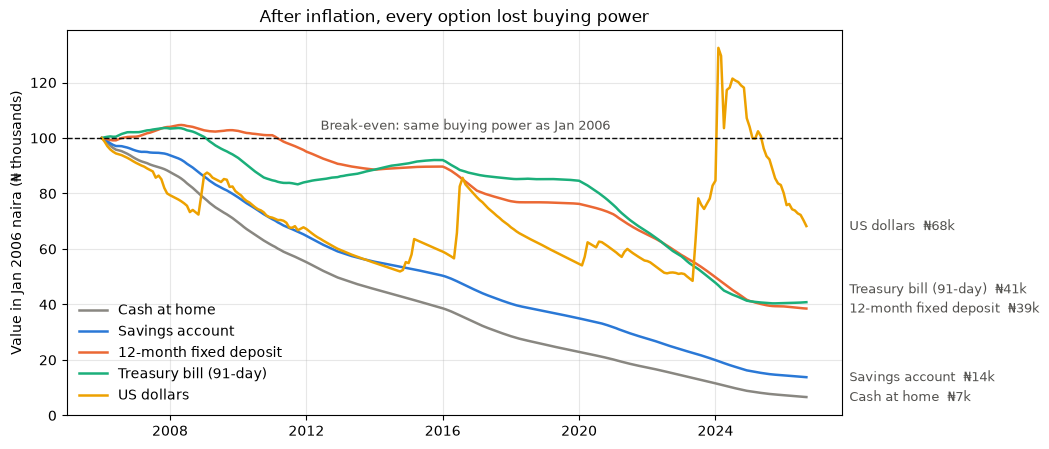

In [264]:
fig, ax = plt.subplots(figsize=(10, 5))
for option in real_value.columns:
    ax.plot(real_value.index, real_value[option] / 1000, color=OPTION_COLORS[option], linewidth=1.8, label=option)

ax.axhline(START_AMOUNT / 1000, color="#0b0b0b", linewidth=1, linestyle="--")
ax.text(pd.Timestamp("2012-06-01"), START_AMOUNT / 1000 + 3, "Break-even: same buying power as Jan 2006",
        fontsize=9, color="#52514e")

ax.set_title("After inflation, every option lost buying power")
ax.set_ylabel("Value in Jan 2006 naira (₦ thousands)")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend(loc="lower left", frameon=False)
label_line_ends(ax, (real_value.iloc[-1] / 1000).to_dict(), "₦{:,.0f}k")
fig.savefig(IMAGES_DIR / "journey_real.png", dpi=150, bbox_inches="tight")
plt.show()

### The headline chart

What ₦100,000 saved in January 2006 can buy today, measured in 2006 naira.

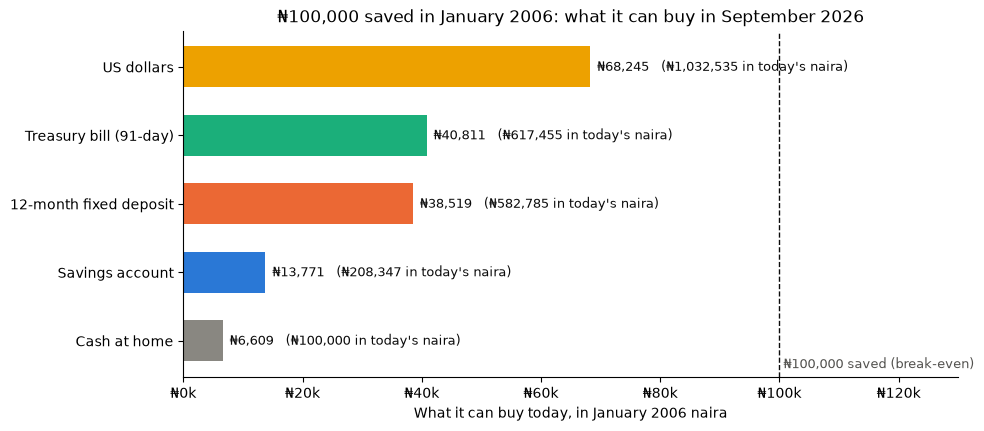

In [265]:
headline = journey.sort_values("in Jan 2006 naira", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(headline.index, headline["in Jan 2006 naira"],
               color=[OPTION_COLORS[o] for o in headline.index], height=0.6)
ax.bar_label(bars, padding=5, fontsize=9, color="#0b0b0b", labels=[
    f"₦{real:,.0f}   (₦{naira:,.0f} in today's naira)"
    for real, naira in zip(headline["in Jan 2006 naira"], headline["naira today"])
])
ax.axvline(START_AMOUNT, color="#0b0b0b", linestyle="--", linewidth=1)
ax.text(START_AMOUNT, len(headline) - 0.6, " ₦100,000 saved (break-even)", fontsize=9, color="#52514e")

ax.invert_yaxis()  # best option at the top
ax.set_xlim(0, START_AMOUNT * 1.3)
ax.xaxis.set_major_formatter(lambda x, _: f"₦{x / 1000:,.0f}k")
ax.set_xlabel("What it can buy today, in January 2006 naira")
ax.set_title(f"₦100,000 saved in January 2006: what it can buy in {latest_month}")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGES_DIR / "headline_100k.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Over 20 years, **every** way of saving lost buying power. ₦100,000 saved in
January 2006 now buys:
- **₦6,610** worth of 2006 goods if kept as **cash at home** (93% of its value gone)
- **₦13,771** in a **savings account**: the balance doubled in naira, but prices rose 15×
- **₦38,519** in **12-month fixed deposits** and **₦40,811** in **91-day Treasury bills**,
  about 4% a year below inflation
- **₦68,245** in **US dollars**: the least bad, but the most uneven. Dollars were *above*
  break-even in 2024–25 (peak about ₦132,500 in Feb 2024), then lost ground when the naira recovered.

Important caveats: dollars use the **official** rate, which many savers couldn't get before
2023, and our price index is approximate (Section 4). No fees or tax are included, so real
savers did a bit worse than shown. This is **not financial advice**.

## 7. Naira vs dollars

**Question:** Did holding US dollars protect savers better than naira deposits?
In which periods, and at what risk?

Dollars pay no interest here, so **all** of their naira return comes from the exchange rate.
If $1 goes from ₦300 to ₦450, dollars gained 50% in naira. If the naira holds steady,
dollars gain nothing, while a deposit at least pays interest.

So whether dollars win depends on **what the naira does**. Let's look at the exchange rate
first, with the big devaluations marked.

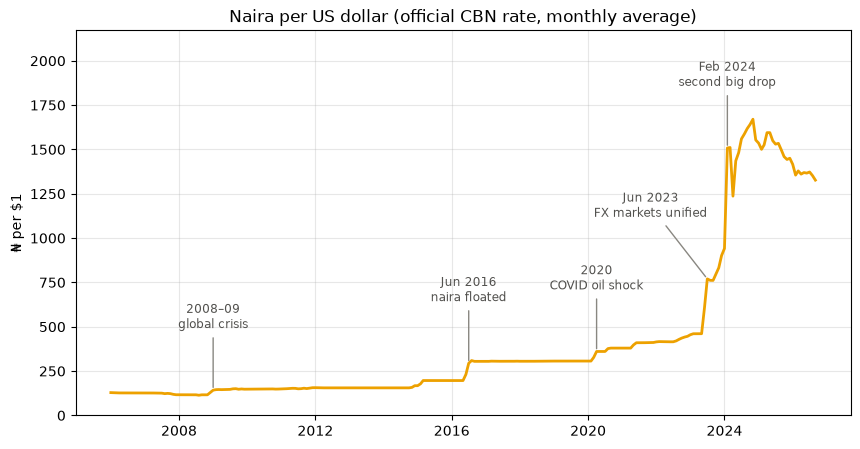

In [266]:
# Each big devaluation: month, label, and how far to move the label left (-) or right (+), in months
DEVALUATIONS = [
    ("2009-01-01", "2008–09\nglobal crisis", 0),
    ("2016-07-01", "Jun 2016\nnaira floated", 0),
    ("2020-04-01", "2020\nCOVID oil shock", 0),
    ("2023-07-01", "Jun 2023\nFX markets unified", -20),
    ("2024-02-01", "Feb 2024\nsecond big drop", 0),
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly["usd_ngn"], color=OPTION_COLORS["US dollars"], linewidth=2)

for date, label, shift_months in DEVALUATIONS:
    when = pd.Timestamp(date)
    rate = monthly.loc[when, "usd_ngn"]
    label_at = (when + pd.DateOffset(months=shift_months), rate + 350)
    ax.annotate(label, xy=(when, rate), xytext=label_at, ha="center", fontsize=8.5,
                color="#52514e", arrowprops={"arrowstyle": "-", "color": "#898781"})

ax.set_title("Naira per US dollar (official CBN rate, monthly average)")
ax.set_ylabel("₦ per $1")
ax.set_ylim(0, monthly["usd_ngn"].max() * 1.3)
ax.grid(alpha=0.3)
fig.savefig(IMAGES_DIR / "usd_ngn.png", dpi=150, bbox_inches="tight")
plt.show()

Between devaluations the official rate barely moved for years at a time (2009–2014,
2017–2019), because the CBN held it in place. Then it jumped all at once.

### Year by year: who won?

The 20-year totals in Section 6 hide **when** each option did well. So we measure each
calendar year's **real return**: the change in buying power from the end of one year to
the end of the next.

Two years are partial: 2006 starts in January, and 2026 ends in September.

In [267]:
# Buying power at the end of each year (Sep for 2026)
year_end = real_value.groupby(real_value.index.year).last()

# Put the Jan 2006 starting value in front, labelled 2005, so 2006's return is Jan → Dec 2006
starting_row = real_value.iloc[[0]].set_axis([2005])
yearly_return = (pd.concat([starting_row, year_end]).pct_change() * 100).dropna().round(1)
yearly_return.index.name = "year"

naira_best = "Treasury bill (91-day)"
yearly_return["dollars beat T-bills?"] = yearly_return["US dollars"] > yearly_return[naira_best]
yearly_return

,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day),US dollars,dollars beat T-bills?
year,,,,,,
2006,-6.9,-4.2,0.4,2.1,-8.3,False
2007,-5.1,-1.7,3.5,1.5,-12.7,False
2008,-10.3,-7.7,-0.9,-2.6,-1.0,True
2009,-11.2,-8.8,-0.3,-7.3,2.0,True
2010,-12.1,-10.0,-1.6,-9.0,-11.6,False
2011,-9.8,-8.5,-5.3,-1.3,-5.2,False
2012,-10.9,-9.4,-5.2,2.3,-11.4,False
2013,-7.8,-5.9,-2.2,2.9,-7.9,False
2014,-7.5,-4.4,0.7,2.7,-0.1,False


In [268]:
dollar_years = yearly_return["dollars beat T-bills?"]
print(f"Dollars beat Treasury bills in {dollar_years.sum()} of {len(dollar_years)} years:",
      list(yearly_return.index[dollar_years]))

Dollars beat Treasury bills in 9 of 21 years: [2008, 2009, 2015, 2016, 2020, 2021, 2022, 2023, 2024]


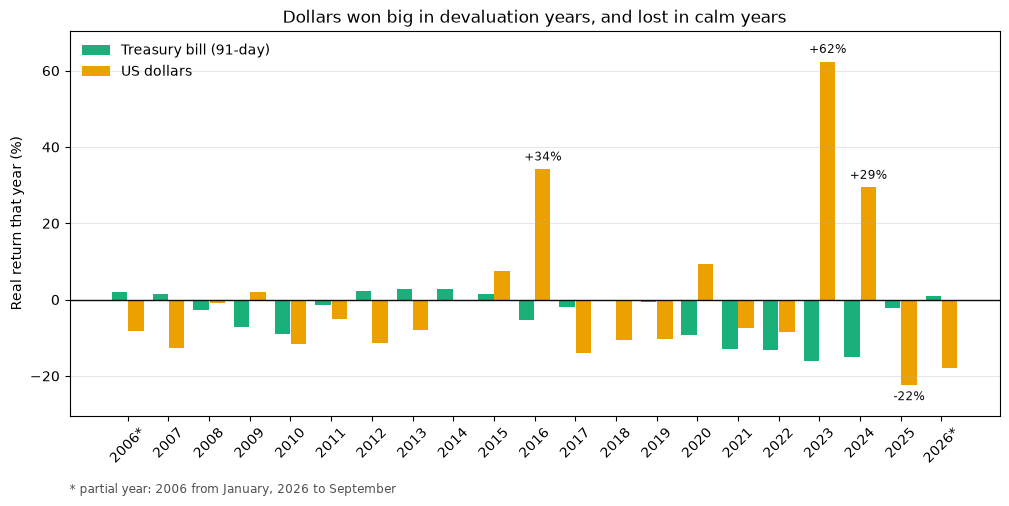

In [269]:
compare_options = [naira_best, "US dollars"]
years_list = yearly_return.index.to_list()
x = range(len(years_list))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(12, 5))
for i, option in enumerate(compare_options):
    offset = (i - 0.5) * bar_width
    ax.bar([pos + offset for pos in x], yearly_return[option], width=bar_width * 0.95,
           color=OPTION_COLORS[option], label=option)

# Label only the big dollar years, so the chart stays readable
for pos, value in zip(x, yearly_return["US dollars"]):
    if abs(value) >= 20:
        ax.text(pos + bar_width / 2, value + (1.5 if value > 0 else -1.5), f"{value:+.0f}%",
                ha="center", va="bottom" if value > 0 else "top", fontsize=8.5, color="#0b0b0b")

ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_ylim(yearly_return["US dollars"].min() - 8, yearly_return["US dollars"].max() + 8)
ax.set_xticks(list(x))
ax.set_xticklabels([f"{y}*" if y in (years_list[0], years_list[-1]) else str(y) for y in years_list],
                   rotation=45)
ax.set_ylabel("Real return that year (%)")
ax.set_title("Dollars won big in devaluation years, and lost in calm years")
ax.text(0, -0.2, "* partial year: 2006 from January, 2026 to September", transform=ax.transAxes,
        fontsize=8.5, color="#52514e")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMAGES_DIR / "usd_vs_tbill_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

### Risk: how bumpy is the ride?

One way to measure risk is **volatility**: how much returns swing up and down. We take
each month's real return, measure how spread out they are with the **standard deviation**,
then multiply by √12 to express it per year (the usual rule for scaling monthly swings
to yearly swings).

Rough guide: about 2% is a smooth ride. About 20% means a year can easily go
+20% or −20% from normal.

In [270]:
monthly_real_return = real_value.pct_change().dropna()

risk = pd.DataFrame({
    "real CAGR (%)": journey["CAGR after inflation (%)"],
    "volatility (% per year)": (monthly_real_return.std() * 12 ** 0.5 * 100).round(1),
    "worst month (%)": (monthly_real_return.min() * 100).round(1),
    "best year (%)": yearly_return[real_value.columns].max(),
    "worst year (%)": yearly_return[real_value.columns].min(),
})
risk

,real CAGR (%),volatility (% per year),worst month (%),best year (%),worst year (%)
Cash at home,-12.3,1.6,-2.5,-5.1,-24.9
Savings account,-9.1,1.4,-1.9,-1.7,-20.0
12-month fixed deposit,-4.5,1.7,-1.7,3.5,-17.6
Treasury bill (91-day),-4.2,2.0,-2.0,2.9,-16.1
US dollars,-1.8,18.7,-20.1,62.4,-22.5


A **risk–return chart** puts both on one picture: up is better (more return), right is
bumpier (more risk). A good option sits **high and to the left**.

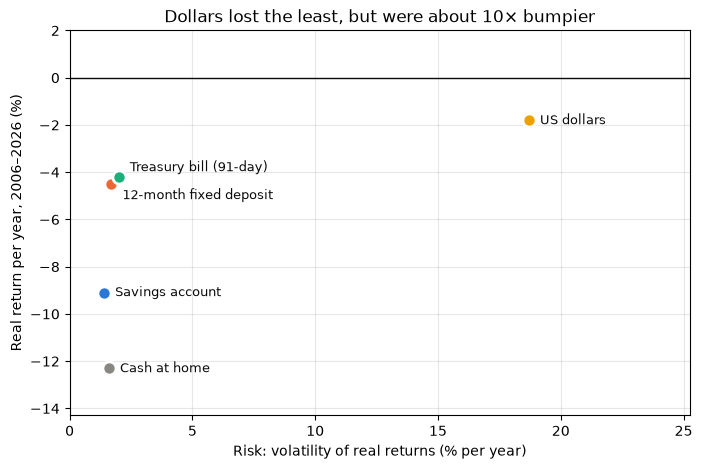

In [271]:
# Move two labels apart so they don't overlap (points right, points up)
label_offsets = {"Treasury bill (91-day)": (8, 7), "12-month fixed deposit": (8, -8)}

fig, ax = plt.subplots(figsize=(8, 5))
for option, row in risk.iterrows():
    ax.scatter(row["volatility (% per year)"], row["real CAGR (%)"], s=90,
               color=OPTION_COLORS[option], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(option, (row["volatility (% per year)"], row["real CAGR (%)"]),
                xytext=label_offsets.get(option, (8, 0)), textcoords="offset points",
                va="center", fontsize=9, color="#0b0b0b")

ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_xlim(0, risk["volatility (% per year)"].max() * 1.35)
ax.set_ylim(risk["real CAGR (%)"].min() - 2, 2)
ax.set_xlabel("Risk: volatility of real returns (% per year)")
ax.set_ylabel("Real return per year, 2006–2026 (%)")
ax.set_title("Dollars lost the least, but were about 10× bumpier")
ax.grid(alpha=0.3)
fig.savefig(IMAGES_DIR / "risk_return.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Dollars protected savers **better over the full 20 years**, keeping 68% of their
buying power against 41% for Treasury bills. But the protection came in **sudden bursts**, not steadily:
- Dollars beat Treasury bills in only **9 of 21 years**. Almost all the gains came in devaluation
  years: **+34% in 2016, +62% in 2023, +29% in 2024** (real returns).
- In calm years, when the official rate was held steady, dollars **lost nearly the full inflation
  rate** because they earn no interest: −14% in 2017, −22.5% in 2025.
- Dollars were about **10 times bumpier** than naira deposits (volatility about 19% a year vs about 2%), with
  a worst month of **−20%** (Apr 2024, when the naira recovered).

So dollars worked as **insurance against devaluation**, and they were costly to hold while
waiting for one. Timing mattered a lot (Section 8 looks at this).

**Caveat:** this uses the **official** rate. Before the 2023 unification, the parallel-market
rate was often far weaker than the official rate, and the official rate was held flat for long stretches.
Savers who bought and sold dollars on the parallel market would have seen a **steadier and probably
larger** dollar gain in naira than shown here. This is **not financial advice**.

## 8. Timing: does it matter when you start?

**Question:** Compare every start month with 1-, 3- and 5-year holding periods. How much
does the result depend on **when** you started saving?

Section 6 followed one saver who started in January 2006. Real savers start whenever
they have money. So we use **rolling windows**: imagine a separate saver starting in
**every month**, holding for 1, 3 or 5 years, and measure each one's real return per year (CAGR).

Each window reuses `growth_path` from Section 6, so a saver who starts in July locks
a July rate, not a January one.

Longer holds have fewer windows: a 5-year saver must have started by September 2021
to finish by September 2026.

In [272]:
HOLDING_YEARS = [1, 3, 5]


def window_real_cagr(start, hold_months):
    """Real return per year (%) for each option, saving from month number `start` for `hold_months`."""
    window = monthly.iloc[start : start + hold_months + 1]
    naira_growth = growth_path(window).iloc[-1]
    price_rise = window["price_index"].iloc[-1] / window["price_index"].iloc[0]
    real_growth = naira_growth / price_rise
    return (real_growth ** (12 / hold_months) - 1) * 100


rows = []
for years in HOLDING_YEARS:
    hold_months = years * 12
    for start in range(len(monthly) - hold_months):
        for option, value in window_real_cagr(start, hold_months).items():
            rows.append({"start": monthly.index[start], "years held": years,
                         "option": option, "real CAGR (%)": value})

rolling = pd.DataFrame(rows)
print(f"{len(rolling):,} results: one per start month, holding period and option")
rolling.head()

3,195 results: one per start month, holding period and option


,start,years held,option,real CAGR (%)
0,2006-01-01,1,Cash at home,-7.502234
1,2006-01-01,1,Savings account,-4.565228
2,2006-01-01,1,12-month fixed deposit,0.489573
3,2006-01-01,1,Treasury bill (91-day),2.096725
4,2006-01-01,1,US dollars,-8.937721


### How often did each option beat inflation?

For each option and holding period: out of all the possible start months, what share
ended with **more** buying power than they started with?

In [273]:
rolling["beat inflation"] = rolling["real CAGR (%)"] > 0

beat_share = (rolling.pivot_table(index="option", columns="years held", values="beat inflation", aggfunc="mean")
              .mul(100).round(1).reindex(OPTION_COLORS.keys()))
beat_share.columns = [f"{y}-year hold: % of start months" for y in beat_share.columns]
beat_share

,1-year hold: % of start months,3-year hold: % of start months,5-year hold: % of start months
option,,,
Cash at home,0.0,0.0,0.0
Savings account,0.0,0.0,0.0
12-month fixed deposit,15.6,6.1,0.5
Treasury bill (91-day),30.0,17.4,15.3
US dollars,29.5,34.3,47.1


### How wide is the range of outcomes?

The **median** is the middle result: half of the savers did better, half did worse. The
**worst** and **best** show how much luck of timing mattered.

In [274]:
outcome_range = (rolling.groupby(["years held", "option"])["real CAGR (%)"]
                 .agg(worst="min", median="median", best="max").round(1))
outcome_range

worst  median   best
years held option                                      
1          12-month fixed deposit  -17.8    -3.3    4.2
           Cash at home            -24.9   -11.3   -5.1
           Savings account         -20.0    -8.8   -1.7
           Treasury bill (91-day)  -17.8    -2.4    3.5
           US dollars              -29.2    -8.1  160.0
3          12-month fixed deposit  -14.2    -4.3    1.2
           Cash at home            -21.0   -11.3   -7.8
           Savings account         -16.6    -8.9   -4.8
           Treasury bill (91-day)  -14.9    -3.1    2.8
           US dollars              -12.6    -3.0   31.1
5          12-month fixed deposit  -11.8    -3.6    0.2
           Cash at home            -18.5   -10.9   -8.8
           Savings account         -14.9    -8.3   -6.5
           Treasury bill (91-day)  -13.4    -3.6    1.7
           US dollars               -9.3    -0.3   17.1

In [275]:
# For each start month, which option did best?
best_rows = rolling.loc[rolling.groupby(["years held", "start"])["real CAGR (%)"].idxmax()]
winner_share = (best_rows.groupby("years held")["option"].value_counts(normalize=True)
                .mul(100).round(1).unstack(fill_value=0))
winner_share

option,12-month fixed deposit,Treasury bill (91-day),US dollars
years held,,,
1,19.0,42.6,38.4
3,24.9,27.2,47.9
5,23.8,21.2,55.0


### Heatmap: start year × holding period

Each cell is the **average** real return per year for savers who started in that year.
**Red** means they lost buying power, **blue** means they beat inflation, and grey is about zero.
Colours stop at ±20% so the ordinary years stay readable; the number in each cell is exact.
Blank cells are windows that haven't finished yet.

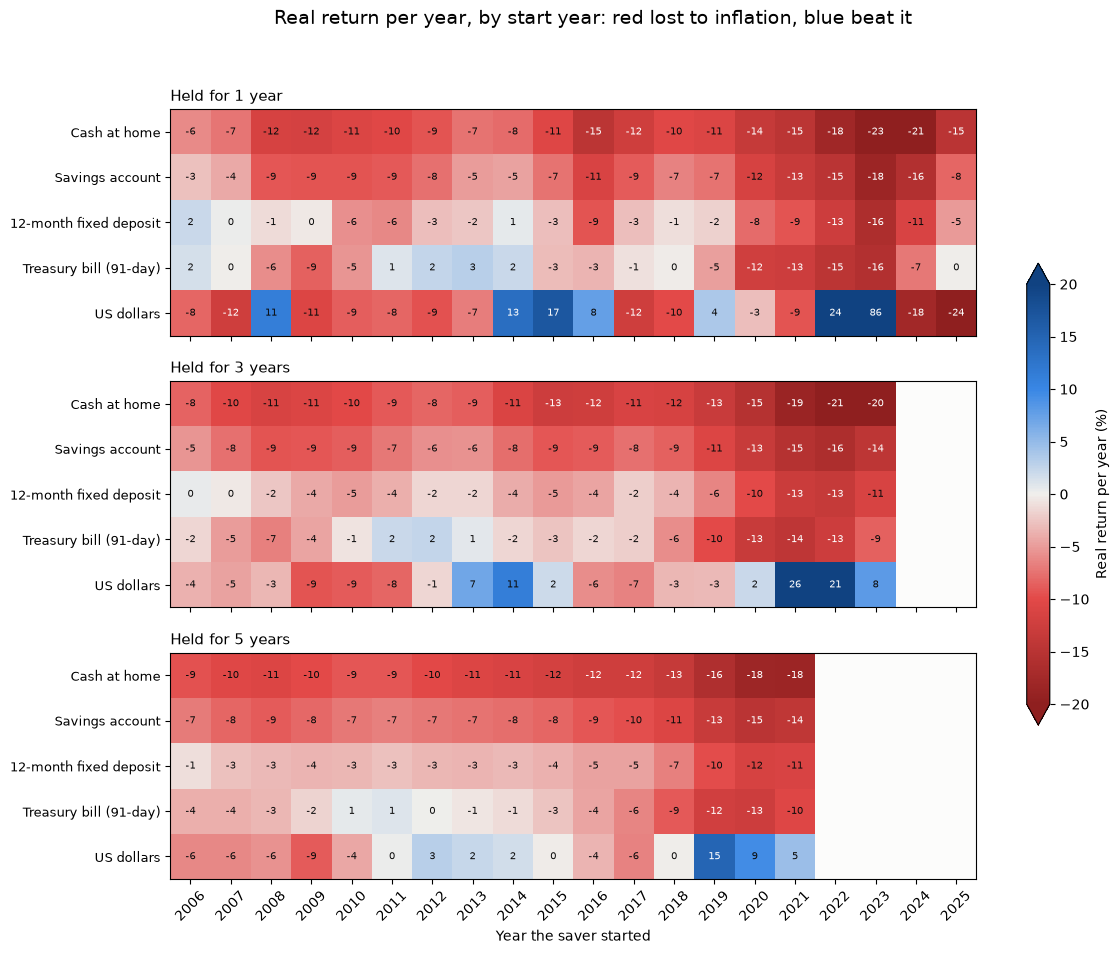

In [276]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Red (lost) ← grey (zero) → blue (gained), with the same number of steps on each side
LOSS_GAIN = LinearSegmentedColormap.from_list("loss_gain", ["#8f1f1f", "#e34948", "#f0efec", "#3987e5", "#104281"])
LOSS_GAIN.set_bad("#fcfcfb")  # blank cells
color_scale = TwoSlopeNorm(vmin=-20, vcenter=0, vmax=20)

all_start_years = sorted(rolling["start"].dt.year.unique())
option_order = list(OPTION_COLORS)

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, years in zip(axes, HOLDING_YEARS):
    table = (rolling[rolling["years held"] == years]
             .assign(start_year=lambda d: d["start"].dt.year)
             .pivot_table(index="option", columns="start_year", values="real CAGR (%)", aggfunc="mean")
             .reindex(index=option_order, columns=all_start_years))

    image = ax.imshow(table, cmap=LOSS_GAIN, norm=color_scale, aspect="auto")

    # Write each value in its cell; white text on the darkest cells
    for row, option in enumerate(table.index):
        for col, year in enumerate(table.columns):
            value = table.loc[option, year]
            if pd.notna(value):
                # round() turns -0.4 into 0, so no cell shows "-0"
                ax.text(col, row, f"{round(value)}", ha="center", va="center", fontsize=7.5,
                        color="white" if abs(value) > 12 else "#0b0b0b")

    ax.set_yticks(range(len(option_order)))
    ax.set_yticklabels(option_order, fontsize=9)
    ax.set_title(f"Held for {years} year{'s' if years > 1 else ''}", loc="left", fontsize=11)

axes[-1].set_xticks(range(len(all_start_years)))
axes[-1].set_xticklabels(all_start_years, rotation=45)
axes[-1].set_xlabel("Year the saver started")
fig.colorbar(image, ax=axes, extend="both", shrink=0.6, label="Real return per year (%)")
fig.suptitle("Real return per year, by start year: red lost to inflation, blue beat it", fontsize=14, x=0.45)
fig.savefig(IMAGES_DIR / "timing_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Timing mattered, but for naira savers it mostly decided **how much** they lost:
- **Savings accounts and cash lost to inflation for every start month and every holding period.**
  No timing could save them.
- **Fixed deposits** beat inflation in only 16% of 1-year windows, 6% of 3-year windows and
  **1 of 189** 5-year windows. **Treasury bills** did a little better: 30%, 17% and 15%.
  Holding longer didn't help naira savers, because the losing stretches lasted many years.
- **Dollars** were the opposite: the longer you held, the better your chances. They beat
  inflation in 30% of 1-year windows but **47% of 5-year windows**, because over 5 years a
  devaluation usually came along. Dollars were the best option for more than half of all 5-year savers.
- **Luck of timing mattered most for dollars.** 1-year real returns ranged from **−29% to
  +160%** a year, depending only on the start month. Over 5 years the range narrowed to −9% to +17%.
- The best starts were **2011–2013 for Treasury bills** (small real gains) and **just before a
  devaluation for dollars** (2013–14, 2020–22). The worst start was **2019–2022 for naira
  options**, losing about 6–14% a year over the following 3 years.

This is **not financial advice**: nobody knows in advance when the next devaluation will come.

## 9. Risk: drawdowns and recovery

**Question:** What was the worst fall from a peak for each option, and how long did it take
to recover, if it ever did?

A **drawdown** is the fall from the **highest value reached so far**. If your savings were
worth ₦120,000 at their best and are now ₦90,000, you're in a 25% drawdown.

Volatility (Section 7) measured how **bumpy** the ride was. A drawdown measures how much it
**hurt** at the worst point, which is closer to how savers actually feel risk.

**Recovery** is when the value climbs back to that old peak. Until then, the saver is
**underwater**.

We measure drawdowns on **real value** (buying power), using the Jan 2006 saver from Section 6.

The key tool is `cummax()`, the **running maximum**: for each month, the highest value
seen up to that point. A small example:

In [277]:
example = pd.Series([100, 120, 90, 130, 110])
pd.DataFrame({
    "value": example,
    "best so far (cummax)": example.cummax(),
    "drawdown": (example / example.cummax() - 1).map("{:.0%}".format),
})

,value,best so far (cummax),drawdown
0,100,100,0%
1,120,120,0%
2,90,120,-25%
3,130,130,0%
4,110,130,-15%


In [278]:
drawdown = real_value / real_value.cummax() - 1  # 0 at a new peak, negative below it
drawdown.iloc[::60].mul(100).round(1)  # every 5 years, in %

,Cash at home,Savings account,12-month fixed deposit,Treasury bill (91-day),US dollars
month,,,,,
2006-01-01,0.0,0.0,0.0,0.0,0.0
2011-01-01,-38.7,-29.3,-3.5,-18.2,-28.7
2016-01-01,-61.4,-49.6,-14.3,-11.2,-41.0
2021-01-01,-79.8,-68.2,-30.7,-26.7,-40.5
2026-01-01,-92.7,-85.6,-62.5,-60.9,-39.5


### The worst drawdown for each option

For each option we find the **deepest** point (the trough), the **peak** before it, and the
first month afterwards when the value got back to that peak, if any.

In [279]:
def worst_drawdown(value):
    """Depth, peak, trough and recovery month of the deepest drawdown in a series of values."""
    falls = value / value.cummax() - 1
    trough = falls.idxmin()
    peak = value.loc[:trough].idxmax()
    after_trough = value.loc[trough:]
    back_to_peak = after_trough[after_trough >= value.loc[peak]]
    recovery = back_to_peak.index[0] if len(back_to_peak) else None
    return falls.min(), peak, trough, recovery


def months_between(start, end):
    return (end.year - start.year) * 12 + (end.month - start.month)


drawdown_rows = []
for option in real_value.columns:
    depth, peak, trough, recovery = worst_drawdown(real_value[option])
    if recovery is None:
        underwater = months_between(peak, latest)
        recovered_text = f"not yet ({underwater / 12:.1f} years and counting)"
    else:
        underwater = months_between(peak, recovery)
        recovered_text = f"{recovery:%b %Y} (after {underwater / 12:.1f} years)"
    drawdown_rows.append({
        "option": option,
        "worst fall (%)": round(depth * 100, 1),
        "peak": f"{peak:%b %Y}",
        "bottom": f"{trough:%b %Y}",
        "back to peak": recovered_text,
        "% of months underwater": round((drawdown[option] < 0).mean() * 100),
    })

drawdown_table = pd.DataFrame(drawdown_rows).set_index("option")
drawdown_table

,worst fall (%),peak,bottom,back to peak,% of months underwater
option,,,,,
Cash at home,-93.4,Jan 2006,Sep 2026,not yet (20.7 years and counting),100
Savings account,-86.2,Jan 2006,Sep 2026,not yet (20.7 years and counting),100
12-month fixed deposit,-63.2,May 2008,Sep 2026,not yet (18.3 years and counting),91
Treasury bill (91-day),-61.0,Apr 2008,Oct 2025,not yet (18.4 years and counting),92
US dollars,-51.5,Jan 2006,May 2023,Feb 2024 (after 18.1 years),99


### The underwater chart

Each panel shows how far below its best value an option was, month by month. The top
line (0%) means "at a new peak". The deeper the shading, the more buying power was lost.

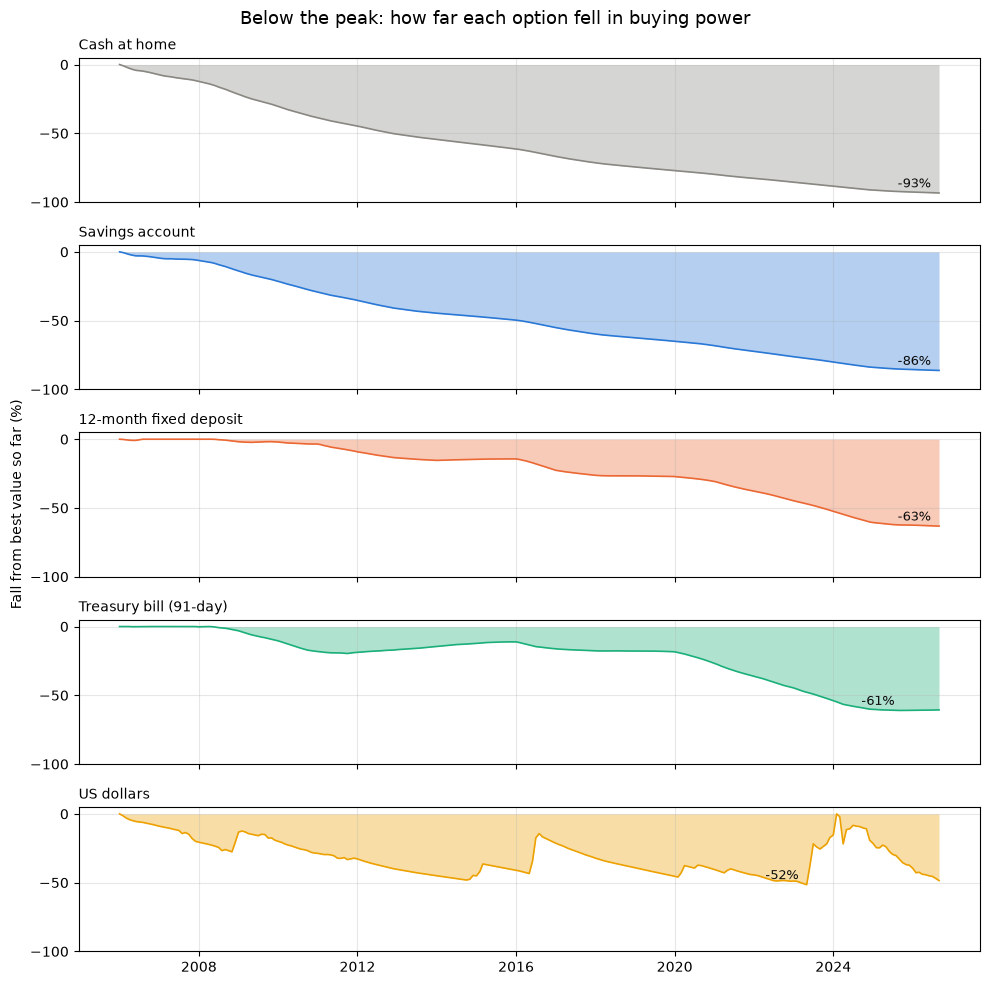

In [280]:
fig, axes = plt.subplots(len(real_value.columns), 1, figsize=(10, 10), sharex=True, sharey=True)
for ax, option in zip(axes, real_value.columns):
    falls = drawdown[option] * 100
    ax.fill_between(falls.index, falls, 0, color=OPTION_COLORS[option], alpha=0.35, linewidth=0)
    ax.plot(falls.index, falls, color=OPTION_COLORS[option], linewidth=1.2)

    worst_month = falls.idxmin()
    ax.annotate(f"{falls.min():.0f}%", xy=(worst_month, falls.min()), xytext=(-6, 4),
                textcoords="offset points", ha="right", fontsize=9, color="#0b0b0b")
    ax.set_title(option, loc="left", fontsize=10)
    ax.set_ylim(-100, 5)
    ax.set_yticks([0, -50, -100])
    ax.grid(alpha=0.3)

axes[len(axes) // 2].set_ylabel("Fall from best value so far (%)")
fig.suptitle("Below the peak: how far each option fell in buying power", fontsize=13)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "drawdowns.png", dpi=150, bbox_inches="tight")
plt.show()

### Every big fall for dollars

The "worst drawdown" only shows one episode. Dollars had more than one, so we list every
fall deeper than 10%. The loop walks through the months, keeping track of the current peak
and the lowest point since then. When the value climbs back above the peak, that episode
is over.

In [281]:
def drawdown_episodes(value, min_depth=0.10):
    """List every fall deeper than `min_depth` (0.10 = 10%): peak, bottom, recovery and depth."""
    episodes = []
    peak_month, peak_value = value.index[0], value.iloc[0]
    low_month, low_value = peak_month, peak_value

    for month, current in value.items():
        if current >= peak_value:  # back at (or above) the peak: the episode is over
            if low_value / peak_value - 1 <= -min_depth:
                episodes.append((peak_month, low_month, month, low_value / peak_value - 1))
            peak_month, peak_value = month, current
            low_month, low_value = month, current
        elif current < low_value:  # a new low inside this episode
            low_month, low_value = month, current

    if low_value / peak_value - 1 <= -min_depth:  # an episode that hasn't recovered yet
        episodes.append((peak_month, low_month, None, low_value / peak_value - 1))

    return pd.DataFrame([{
        "peak": f"{peak:%b %Y}",
        "bottom": f"{low:%b %Y}",
        "recovered": "not yet" if end is None else f"{end:%b %Y}",
        "fall (%)": round(depth * 100, 1),
    } for peak, low, end, depth in episodes])


drawdown_episodes(real_value["US dollars"])

,peak,bottom,recovered,fall (%)
0,Jan 2006,May 2023,Feb 2024,-51.5
1,Feb 2024,Sep 2026,not yet,-48.5


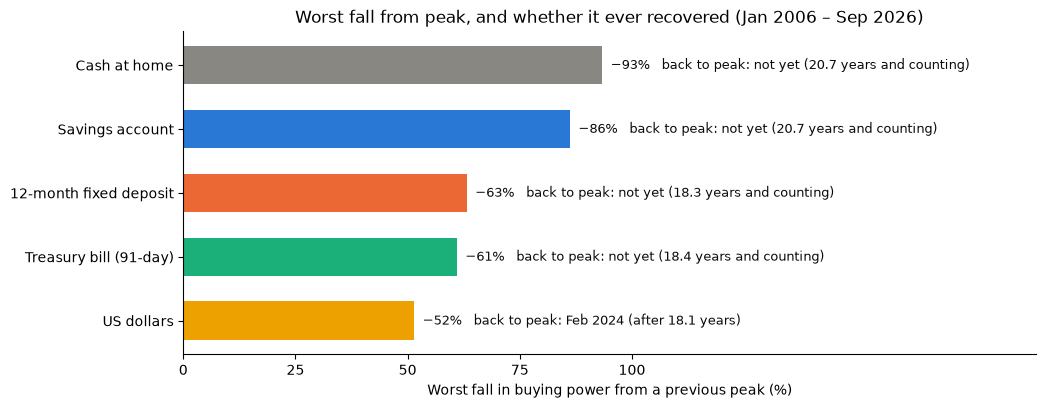

In [282]:
# Bar length = size of the fall, so the deepest fall is the longest bar
fall_size = -drawdown_table["worst fall (%)"]
ordered = fall_size.sort_values()

fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.barh(ordered.index, ordered.values,
               color=[OPTION_COLORS[o] for o in ordered.index], height=0.6)
ax.bar_label(bars, padding=6, fontsize=9, color="#0b0b0b",
             labels=[f"−{size:.0f}%   back to peak: {drawdown_table.loc[option, 'back to peak']}"
                     for option, size in ordered.items()])
ax.set_xlim(0, 190)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Worst fall in buying power from a previous peak (%)")
ax.set_title("Worst fall from peak, and whether it ever recovered (Jan 2006 – Sep 2026)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGES_DIR / "worst_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Measured in buying power, **every** option suffered a deep fall, and the naira
options **never recovered**:
- **Cash** and **savings accounts** were at their best on the first day (Jan 2006) and fell
  **93%** and **86%** without ever coming back.
- **Fixed deposits** and **Treasury bills** peaked in **2008**, then lost about **61–63%** of their
  buying power. More than 18 years later, they still haven't returned to that peak.
- **Dollars** fell **51.5%** from Jan 2006 to May 2023, staying underwater for 18 years, then
  recovered **in just 9 months** during the 2023–24 devaluations. Since that Feb 2024 peak they
  have fallen **48.5%** again as the naira recovered.

So the naira options lost buying power **slowly and steadily**, while dollars lost slowly and
then **recovered in sudden jumps**. A saver in either was below their earlier best in more than
90% of months. Drawdowns are measured for a saver who started in Jan 2006, and this is
**not financial advice**.

## 10. Policy: did savers benefit when the CBN raised rates?

**Question:** Did deposit rates follow the CBN's policy rate (MPR), or stay low? Did savers
do better when the CBN raised the MPR?

The MPR is the CBN's main interest rate (Section 3). In theory, when the CBN raises it,
banks pay more on deposits and savers benefit. Let's check:
1. **Do the rates move together?** A chart of the MPR and the rates savers get.
2. **Pass-through:** when the MPR rises 1 point, how much do savers' rates rise?
3. **Hiking vs cutting periods:** were real returns better when the CBN was raising rates?

The MPR started in Dec 2006, so this section covers Dec 2006 onwards.

In [ ]:
RATE_COLUMNS_FOR_SAVERS = {
    "Savings account": "savingsDeposit",
    "12-month fixed deposit": "twelveMonthsDeposit",
    "Treasury bill (91-day)": "treasuryBill",
}
policy = monthly.loc[monthly["mpr"].notna()]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(policy.index, policy["mpr"], color="#0b0b0b", linewidth=2.2, label="MPR (CBN policy rate)")
for option, column in RATE_COLUMNS_FOR_SAVERS.items():
    ax.plot(policy.index, policy[column], color=OPTION_COLORS[option], linewidth=1.5, label=option)
ax.plot(policy.index, policy["inflation"], color="#52514e", linewidth=1.2, linestyle="--", label="Inflation")

ax.set_title("The MPR climbed after 2022; savings rates barely moved")
ax.set_ylabel("% per year")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend(loc="upper left", frameon=False, fontsize=9)
label_line_ends(ax, {
    "MPR": policy["mpr"].iloc[-1],
    "Inflation": policy["inflation"].iloc[-1],
    **{option: policy[column].iloc[-1] for option, column in RATE_COLUMNS_FOR_SAVERS.items()},
}, "{:.1f}%")
fig.savefig(IMAGES_DIR / "mpr_vs_rates.png", dpi=150, bbox_inches="tight")
plt.show()

### The gap between the MPR and what savers get

The **spread** is the MPR minus each rate. A growing spread means savers are getting a
smaller share of the CBN's rate.

In [ ]:
spread = pd.DataFrame({option: policy["mpr"] - policy[column]
                       for option, column in RATE_COLUMNS_FOR_SAVERS.items()})
yearly_spread = spread.groupby(spread.index.year).mean().round(1)
yearly_spread.index.name = "year"
yearly_spread

### Pass-through

We compare **12-month changes**: how much the MPR moved over a year, and how much each rate
moved over the same year. Then we fit the best straight line through the points with
`np.polyfit`. Its **slope** is the pass-through:
- **1.0**: savers' rate moves point for point with the MPR
- **0.5**: it moves half as much
- **0**: it ignores the MPR

The **correlation** (−1 to 1) shows how tightly the points follow that line.

In [ ]:
import numpy as np

yearly_change = policy[["mpr"] + list(RATE_COLUMNS_FOR_SAVERS.values())].diff(12).dropna()

pass_through = {}
for option, column in RATE_COLUMNS_FOR_SAVERS.items():
    slope, intercept = np.polyfit(yearly_change["mpr"], yearly_change[column], 1)
    pass_through[option] = {
        "pass-through (slope)": round(slope, 2),
        "correlation": round(yearly_change["mpr"].corr(yearly_change[column]), 2),
    }

pd.DataFrame(pass_through).T

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharex=True, sharey=True)
line_x = np.array([yearly_change["mpr"].min(), yearly_change["mpr"].max()])

for ax, (option, column) in zip(axes, RATE_COLUMNS_FOR_SAVERS.items()):
    ax.scatter(yearly_change["mpr"], yearly_change[column], s=14, alpha=0.5, color=OPTION_COLORS[option])
    slope, intercept = np.polyfit(yearly_change["mpr"], yearly_change[column], 1)
    ax.plot(line_x, intercept + slope * line_x, color="#0b0b0b", linewidth=1.5)
    ax.plot(line_x, line_x, color="#898781", linewidth=1, linestyle=":")  # full pass-through
    ax.set_title(f"{option}\npass-through {slope:.2f}", fontsize=10)
    ax.axhline(0, color="#c3c2b7", linewidth=0.8)
    ax.axvline(0, color="#c3c2b7", linewidth=0.8)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("12-month change in the rate (points)")
axes[1].set_xlabel("12-month change in the MPR (points)")
axes[0].text(line_x[1], line_x[1] + 0.5, "dotted: full pass-through", fontsize=8, color="#52514e",
             ha="right", va="bottom")
fig.suptitle("When the MPR moved, savings rates moved a quarter as much; T-bills moved more", fontsize=12)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "pass_through.png", dpi=150, bbox_inches="tight")
plt.show()

### Did savers do better when the CBN was raising rates?

We label each month by what the CBN did over the **previous 12 months**: **raised** the MPR,
**cut** it, or **held** it. Then we compare the average real rate (Section 5) in each group.

(The first 12 months of the MPR have no label, because they have no year before them.)

In [ ]:
mpr_change = policy["mpr"].diff(12)
policy_stance = pd.cut(mpr_change, bins=[-100, -0.01, 0.01, 100], labels=["cut", "held", "raised"])

stance_table = real_rates.loc[policy.index].groupby(policy_stance, observed=True).mean().round(1)
stance_table["months"] = policy_stance.value_counts()
stance_table["average inflation (%)"] = policy["inflation"].groupby(policy_stance, observed=True).mean().round(1)
stance_table["inflation change over the year (points)"] = (
    policy["inflation"].diff(12).groupby(policy_stance, observed=True).mean().round(1))
stance_table

In [ ]:
real_mpr = ((1 + policy["mpr"] / 100) / (1 + policy["inflation"] / 100) - 1) * 100
print(f"The MPR itself was below inflation in {(real_mpr < 0).mean():.0%} of months since Dec 2006.")

**Finding:** Savers got **little of the CBN's rate**, and rate hikes didn't rescue them:
- **Deposit rates barely followed the MPR.** When the MPR rose 1 point over a year, savings
  account rates rose only about **0.25** points, and 12-month deposits about **0.6**. Treasury
  bills, which are sold at auction, moved **more** than the MPR (about **1.3**).
- The **gap between the MPR and the savings rate** widened from about **6 points in 2007** to about
  **19 points in 2024–26**. In September 2026 the MPR was 23%, but savings accounts paid 5.4%.
- **Savers did worse, not better, in hiking periods.** Real rates were lowest when the CBN had been
  raising the MPR (T-bills about −6%, savings about −12%) and best when it held steady (T-bills about −2%).
  That's because the CBN raised rates **after** inflation had already climbed: in hiking periods inflation
  averaged 18% and was still rising. The hikes chased inflation instead of getting ahead of it.
- The MPR itself was **below inflation in about half of all months**.
- The exception is **2025–26**: after the 2024 hikes, inflation fell while T-bill rates stayed
  near 16%, and T-bills paid a **positive real rate** for the first time in about 10 years.
  Bank deposit rates didn't follow.

This shows patterns that happened together, not proof of cause and effect, and it's **not financial advice**.